# NETFLIX CUSTOMER INTELLIGENCE & AI ANALYTICS COPILOT

## An End-to-End Data Science, Machine Learning and AI Analytics Project

### 1. Introduction

The streaming industry generates large volumes of customer data through subscriptions, viewing activity, payments, customer feedback and support interactions. Analysing this information is essential for understanding customer behaviour, improving customer satisfaction and reducing subscription cancellations.

The Netflix Customer Intelligence & AI Analytics Copilot project aims to develop an integrated analytical platform that uses data analytics, machine learning and artificial intelligence to understand customer behaviour and support data-driven business decisions.

The project combines multiple datasets to analyse customer engagement, predict churn, identify customer segments, estimate Customer Lifetime Value (CLV) and generate actionable business insights.

### 2. Problem Statement

Customer information is distributed across multiple datasets, making it difficult to obtain a unified understanding of customer behaviour. Businesses need an effective analytical solution to identify customers who may discontinue their subscriptions, understand the reasons behind churn and develop appropriate customer retention strategies.

This project addresses these challenges by integrating customer information and applying data analytics, predictive modelling and AI-powered business intelligence.

### 3. Project Objectives

1. Perform data understanding and data quality assessment.
2. Clean and transform the available datasets.
3. Perform exploratory data analysis to identify customer behaviour patterns.
4. Answer business questions using SQL.
5. Develop customer-level analytical features.
6. Build a machine learning model for customer churn prediction.
7. Perform customer segmentation.
8. Predict Customer Lifetime Value.
9. Apply model explainability techniques.
10. Develop an AI Analytics Copilot.
11. Build an interactive Streamlit dashboard.

### 4. Project Methodology

The project follows a structured data science workflow consisting of data understanding, data preparation, exploratory analysis, SQL analytics, feature engineering, machine learning, model evaluation, AI integration and application development.

### 5. Tools and Technologies

- Programming Language: Python
- Data Manipulation: Pandas, NumPy
- Data Visualization: Matplotlib, Seaborn, Plotly
- Database: SQL
- Machine Learning: Scikit-learn, XGBoost
- Model Explainability: SHAP
- AI Integration: Large Language Models and Retrieval-Augmented Generation
- Application Development: Streamlit

### 6. Expected Outcome

The expected outcome is an integrated customer intelligence platform that provides insights into customer behaviour, predicts churn, identifies customer segments, estimates customer lifetime value and supports business decisions through an AI-powered analytics interface.

# PHASE 1: DATA UNDERSTANDING AND DATA PROFILING

## 1.1 Introduction

Data understanding is the first stage of the data science workflow. It involves examining the available datasets to understand their structure, characteristics, quality and relationships.

The Netflix project contains nine datasets representing different business activities, including customer information, subscriptions, content, viewing activity, payments, customer support, feedback and churn labels.

Before performing data cleaning and exploratory data analysis, it is important to understand the information available in each dataset.

## 1.2 Objectives

- Load and inspect all nine datasets.
- Understand dataset dimensions and column structures.
- Identify numerical and categorical variables.
- Examine missing values and duplicate records.
- Understand the relationships between datasets.
- Identify potential data quality issues.

## 1.3 Methodology

Python and Pandas will be used to inspect and profile the datasets. The original data will remain unchanged during this phase. The findings will guide the data cleaning and ETL process in the next phase.

In [ ]:
# PHASE 1: DATA UNDERSTANDING AND DATA PROFILING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
import os
import glob

csv_files = glob.glob("/content/**/*.csv", recursive=True)

print("CSV FILES AVAILABLE IN COLAB:\n")

for file in csv_files:
    print(file)

CSV FILES AVAILABLE IN COLAB:

/content/customers (3).csv
/content/subscriptions (1).csv
/content/subscription_plans.csv
/content/viewing_activity.csv
/content/support_tickets (1).csv
/content/payments (2).csv
/content/churn_labels.csv
/content/customer_feedback (2).csv
/content/content.csv
/content/netflix_reports/dataset_overview.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv


### 1.4 Loading the Datasets

The Netflix project consists of nine CSV datasets containing information about customers, subscription plans, subscription history, streaming content, viewing activity, payment transactions, customer support tickets, customer feedback and churn labels.

In this step, all nine datasets are imported into the Python environment using the Pandas library.

Each dataset is stored in a separate DataFrame to support individual analysis and further integration. These datasets will be used throughout the project for data cleaning, exploratory data analysis, SQL business analytics and machine learning.

The original datasets are preserved without modification at this stage.

In [ ]:
# 1.4 LOADING THE NETFLIX DATASETS

customers = pd.read_csv("/content/customers (3).csv")

subscriptions = pd.read_csv("/content/subscriptions (1).csv")

subscription_plans = pd.read_csv("/content/subscription_plans.csv")

viewing_activity = pd.read_csv("/content/viewing_activity.csv")

support_tickets = pd.read_csv("/content/support_tickets (1).csv")

payments = pd.read_csv("/content/payments (2).csv")

churn_labels = pd.read_csv("/content/churn_labels.csv")

customer_feedback = pd.read_csv("/content/customer_feedback (2).csv")

content = pd.read_csv("/content/content.csv")


# Store all datasets in a dictionary

datasets = {
    "Customers": customers,
    "Subscriptions": subscriptions,
    "Subscription Plans": subscription_plans,
    "Viewing Activity": viewing_activity,
    "Support Tickets": support_tickets,
    "Payments": payments,
    "Churn Labels": churn_labels,
    "Customer Feedback": customer_feedback,
    "Content": content
}

print("All nine Netflix datasets loaded successfully!")

All nine Netflix datasets loaded successfully!


### 1.5 Dataset Dimensions and Overview

Dataset dimensions provide information about the number of records and attributes available in each dataset.

The number of rows represents the total observations, whereas the number of columns represents the variables describing those observations.

This analysis helps us understand the size of each dataset and identify the volume of information available for further processing.

In [ ]:
# 1.5 DATASET DIMENSIONS AND OVERVIEW

dataset_overview = []

for name, df in datasets.items():

    dataset_overview.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Total Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

dataset_overview_df = pd.DataFrame(dataset_overview)

display(dataset_overview_df)

,Dataset,Rows,Columns,Total Missing Values,Duplicate Rows
0,Customers,8048,12,9517,48
1,Subscriptions,8875,10,21768,0
2,Subscription Plans,3,6,0,0
3,Viewing Activity,66422,9,1195,0
4,Support Tickets,6120,11,3056,0
5,Payments,110735,8,214264,0
6,Churn Labels,8000,4,12018,0
7,Customer Feedback,5046,6,0,0
8,Content,500,9,0,0


### 1.6 Initial Dataset Profiling

The dataset overview provides an initial understanding of the structure and size of the available data.

The results include the number of records, attributes, missing values and exact duplicate rows in each dataset.

These measurements will be used as a baseline for evaluating the effectiveness of the data cleaning process in Phase 2.

In [ ]:
# 1.6 SAVE INITIAL PROFILING RESULTS

import os

os.makedirs("/content/netflix_reports", exist_ok=True)

dataset_overview_df.to_csv(
    "/content/netflix_reports/dataset_overview.csv",
    index=False
)

print("Dataset overview saved successfully.")

Dataset overview saved successfully.


### 1.7 Dataset Overview – Results and Observations

After successfully loading all nine datasets, an initial profiling analysis was performed to examine their dimensions, missing values and duplicate records.

The analysis identified a total of **213,749 records** across the nine datasets.

The Payments dataset contains the highest number of records, with 110,735 rows and 8 columns. This represents the largest dataset in the project and contains transaction-level information.

The Viewing Activity dataset contains 66,422 records, providing detailed information about customer viewing behaviour.

The Customers dataset contains 8,048 records and 12 attributes. It also contains 48 exact duplicate rows, which require further investigation during data cleaning.

The Subscription Plans and Content datasets contain no missing values or duplicate records in the initial profiling results.

#### Key Findings

1. The Payments dataset has the highest record volume, containing 110,735 transactions.
2. The Viewing Activity dataset contains 66,422 viewing records, making it an important source for customer engagement analysis.
3. The Customers dataset contains 48 exact duplicate rows.
4. The Customers dataset contains 9,517 missing values across its attributes.
5. The Subscriptions dataset contains 21,768 missing values, which require column-level investigation.
6. The Payments dataset contains 214,264 missing values across its attributes.
7. The Churn Labels dataset contains 12,018 missing values.
8. The Subscription Plans, Customer Feedback and Content datasets have no missing values according to the initial overview.

#### Business Implications

The large volume of payment and viewing activity records provides opportunities to analyse transaction behaviour and customer engagement.

Missing values in customer, subscription, payment and churn information must be investigated carefully before further analysis.

In particular, missing values must not be removed blindly because some represent valid business conditions, such as ongoing subscriptions without an end date.

The duplicate customer records also need to be investigated to avoid inaccurate customer counts and incorrect dataset relationships.

### 1.8 Data Type Analysis

Data type analysis is performed to understand how information is stored within each dataset.

Each variable may contain numerical, categorical, date or identifier information. Identifying the correct data types is important because it determines the preprocessing techniques and analytical operations that can be applied.

For example, date columns must be converted into datetime format for time-based analysis, while categorical variables may require encoding before machine learning.

In this section, the data types and non-null record counts of all columns will be examined to identify variables that may require conversion or standardization.

In [ ]:
# 1.8 DATA TYPE ANALYSIS

for name, df in datasets.items():

    print("\n" + "="*80)
    print("DATASET:", name.upper())
    print("="*80)

    data_type_report = pd.DataFrame({
        "Column Name": df.columns,
        "Data Type": df.dtypes.values,
        "Non-Null Values": df.notnull().sum().values,
        "Unique Values": df.nunique().values
    })

    display(data_type_report)


DATASET: CUSTOMERS


,Column Name,Data Type,Non-Null Values,Unique Values
0,customer_id,object,8048,8000
1,first_name,object,8048,138
2,last_name,object,8048,100
3,age,float64,7726,62
4,gender,object,8048,4
5,country,object,7639,83
6,state_or_region,float64,0,0
7,city,object,7564,88
8,registration_date,object,8048,2573
9,acquisition_channel,object,8048,8



DATASET: SUBSCRIPTIONS


,Column Name,Data Type,Non-Null Values,Unique Values
0,subscription_id,object,8875,8875
1,customer_id,object,8875,8000
2,plan_id,object,8875,3
3,subscription_start_date,object,8875,2620
4,subscription_end_date,object,875,670
5,subscription_status,object,8875,3
6,auto_renew,bool,8875,2
7,cancellation_date,object,1991,271
8,cancellation_reason,object,1991,11
9,monthly_price,float64,8875,3



DATASET: SUBSCRIPTION PLANS


,Column Name,Data Type,Non-Null Values,Unique Values
0,plan_id,object,3,3
1,plan_name,object,3,3
2,monthly_price,float64,3,3
3,video_quality,object,3,3
4,max_devices,int64,3,3
5,advertisements,object,3,2


... (8 outputs left out)


DATASET: CUSTOMER FEEDBACK


,Column Name,Data Type,Non-Null Values,Unique Values
0,feedback_id,object,5046,5046
1,customer_id,object,5046,3561
2,feedback_date,object,5046,1766
3,rating,int64,5046,5
4,feedback_text,object,5046,13
5,sentiment_label,object,5046,3



DATASET: CONTENT


,Column Name,Data Type,Non-Null Values,Unique Values
0,content_id,object,500,500
1,title,object,500,500
2,content_type,object,500,5
3,genre,object,500,16
4,release_year,int64,500,29
5,duration_minutes,int64,500,117
6,content_language,object,500,13
7,production_country,object,500,20
8,maturity_rating,object,500,7


### 1.9 Numerical and Categorical Variable Analysis

Numerical and categorical variables provide different types of information about customers and business operations.

Numerical variables represent measurable quantities such as age, viewing duration, payment amounts and subscription prices. These variables can be examined using descriptive statistical measures.

Categorical variables represent classifications such as country, subscription type, device category, payment status and content genre. Their frequency distributions help identify common categories and potential inconsistencies.

This analysis provides an initial understanding of the variables available for exploratory data analysis and feature engineering.

In [ ]:
# 1.9 NUMERICAL AND CATEGORICAL VARIABLE SUMMARY

for name, df in datasets.items():

    print("\n" + "="*80)
    print("NUMERICAL VARIABLES:", name.upper())
    print("="*80)

    numerical_df = df.select_dtypes(include=np.number)

    if not numerical_df.empty:
        display(numerical_df.describe().T)

    print("\nCATEGORICAL VARIABLES:", name.upper())

    categorical_df = df.select_dtypes(
        include=["object", "category", "bool"]
    )

    for column in categorical_df.columns:

        print("\nColumn:", column)

        display(
            categorical_df[column]
            .value_counts(dropna=False)
            .head(10)
            .to_frame("Frequency")
        )


NUMERICAL VARIABLES: CUSTOMERS


,count,mean,std,min,25%,50%,75%,max
age,7726.0,32.655449,11.281585,2.0,25.0,32.0,40.0,145.0
state_or_region,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



CATEGORICAL VARIABLES: CUSTOMERS

Column: customer_id


,Frequency
customer_id,
CUST006490,2
CUST007864,2
CUST007774,2
CUST007355,2
CUST001132,2
CUST004346,2
CUST006091,2
CUST006093,2
CUST006691,2



Column: first_name


,Frequency
first_name,
Oliver,124
Isabella,110
Chidi,80
Aarav,74
Matthew,74
Karen,74
Valentina,74
Amina,73
Anika,71


... (126 outputs left out)


Column: production_country


,Frequency
production_country,
India,96
United States,92
United Kingdom,30
Germany,29
France,25
Canada,22
Brazil,21
Japan,20
South Korea,20



Column: maturity_rating


,Frequency
maturity_rating,
PG-13,81
NR,77
TV-14,76
TV-MA,70
R,69
PG,67
G,60


### 1.9 Numerical and Categorical Variable Analysis – Results and Observations

The numerical and categorical analysis provided an initial understanding of customer characteristics, subscription information, viewing behaviour, payment activity, support interactions, churn labels, customer feedback and content metadata.

**1. Customer Dataset**
- The average customer age is approximately 32.66 years, with a median age of 32 years.
- The age values range from 2 to 145, indicating that some records may contain unusual or invalid values that require validation.
- Individual customers form the largest customer segment, with 4,412 records.
- Organic Search is the most frequent acquisition channel, with 1,799 records.
- The United States and India are the two most frequently represented countries in the displayed results.

**2. Subscription Dataset**
- The dataset contains 8,875 subscription records across three subscription plans.
- Plan ID `PLAN01` appears most frequently, with 3,671 records.
- There are 6,009 Active, 1,991 Cancelled and 875 Plan Changed subscription records.
- The average monthly subscription price is approximately 13.45.
- Multiple subscription records can belong to the same customer, which is valid for customers who change plans.

**3. Subscription Plans Dataset**
- The dataset contains three plans: Basic, Standard and Premium.
- Monthly prices range from 6.99 to 22.99.
- Maximum supported devices range from 1 to 4.
- The plans differ in video quality and advertisement availability.

**4. Viewing Activity Dataset**
- The average watch duration is approximately 49.43 minutes.
- The average completion percentage is approximately 70.47%.
- Smart TV is the most frequently recorded device category.
- Device values contain formatting variations, such as `Smart TV`, `SmartTV`, `smart tv` and `SMART TV`. These will require standardisation.
- The maximum watch duration and session duration are unusually high and should be investigated during data validation.

**5. Support Tickets Dataset**
- The average ticket resolution time is approximately 18 hours.
- The average customer satisfaction score is approximately 3.26 out of 5.
- Billing & Payments is the most frequent support issue category, with 1,709 tickets.
- The ticket date column contains an invalid date value (`2025-13-45`), which must be handled during date conversion and validation.

**6. Payments Dataset**
- The dataset contains 110,735 payment records.
- The average payment amount is approximately 13.75.
- Credit Card is the most frequently used payment method, with 33,249 records.
- There are 103,529 successful payments and 7,206 failed payments.
- The `subscription_id` column contains no non-null values. This is an important data limitation and will need to be considered when linking payments with subscriptions.

**7. Churn Labels Dataset**
- The dataset contains 8,000 customer-level churn records.
- There are 1,991 customers labelled as churned and 6,009 labelled as not churned.
- The churned records represent approximately 24.89% of the dataset.
- The most frequent displayed churn reason is `Too expensive`, with 365 records.

**8. Customer Feedback Dataset**
- The average customer rating is approximately 3.16 out of 5.
- Positive sentiment is the largest sentiment category, with 1,978 records.
- Neutral sentiment accounts for 1,606 records, while negative sentiment accounts for 1,462 records.
- Feedback text and sentiment labels can support customer experience analysis and retention insights.

**9. Content Dataset**
- The dataset contains 500 content records.
- Movies account for 216 records, while TV Shows account for 144 records.
- The average content duration is approximately 69.57 minutes.
- English and Hindi are the two most frequently represented content languages in the displayed results.

**Overall Observation**

The numerical and categorical analysis reveals useful information about customer behaviour, subscription patterns, viewing engagement, payment performance, support experience, churn and content distribution.

It also identifies potential data-quality issues, including unusual numerical values, inconsistent category formatting, invalid dates and columns with extensive missing values. These issues will be investigated in the data-cleaning and preprocessing phase.

No records have been removed or modified during this analysis. The findings are preliminary and will be validated further before feature engineering and machine learning.

### 1.10 Missing Value Analysis

Missing value analysis is performed to identify incomplete records and understand the extent of missing information across all nine datasets.

Missing values can affect statistical analysis, visualisations, customer segmentation and machine learning models. Therefore, it is necessary to examine missing values at the individual column level before deciding how to handle them.

The analysis includes:
- Total missing values in each column.
- Percentage of missing values in each column.
- Columns with no missing values.
- Columns with a high proportion of missing values.
- Potentially meaningful missing values based on business context.

Missing values will not be removed or replaced automatically. Their treatment will depend on the meaning of each field and the dataset relationships defined in the project documentation.

In [ ]:
# 1.10 MISSING VALUE ANALYSIS

missing_summary = {}

for name, df in datasets.items():

    print("\n" + "="*80)
    print("MISSING VALUE ANALYSIS:", name.upper())
    print("="*80)

    missing_count = df.isnull().sum()
    missing_percentage = (missing_count / len(df)) * 100

    summary = pd.DataFrame({
        "Missing Values": missing_count,
        "Missing Percentage": missing_percentage.round(2)
    })

    summary = summary[summary["Missing Values"] > 0]
    summary = summary.sort_values(
        by="Missing Percentage",
        ascending=False
    )

    missing_summary[name] = summary

    if not summary.empty:
        display(summary)
    else:
        print("No missing values found in this dataset.")


MISSING VALUE ANALYSIS: CUSTOMERS


,Missing Values,Missing Percentage
state_or_region,8048,100.00
city,484,6.01
country,409,5.08
age,322,4.00
preferred_language,254,3.16



MISSING VALUE ANALYSIS: SUBSCRIPTIONS


,Missing Values,Missing Percentage
subscription_end_date,8000,90.14
cancellation_date,6884,77.57
cancellation_reason,6884,77.57



MISSING VALUE ANALYSIS: SUBSCRIPTION PLANS
No missing values found in this dataset.

MISSING VALUE ANALYSIS: VIEWING ACTIVITY


,Missing Values,Missing Percentage
device_type,664,1.0
completion_percentage,531,0.8


... (3 outputs left out)

,Missing Values,Missing Percentage
subscription_id,110735,100.00
failed_payment_reason,103529,93.49



MISSING VALUE ANALYSIS: CHURN LABELS


,Missing Values,Missing Percentage
churn_date,6009,75.11
churn_reason,6009,75.11



MISSING VALUE ANALYSIS: CUSTOMER FEEDBACK
No missing values found in this dataset.

MISSING VALUE ANALYSIS: CONTENT
No missing values found in this dataset.


### 1.10 Missing Value Analysis – Results and Observations

The column-level missing value analysis identified missing information across six of the nine datasets. Subscription Plans, Customer Feedback and Content contain no missing values.

**1. Customers**
- `state_or_region` is completely empty, with 8,048 missing values (100%).
- `city` has 484 missing values (6.01%).
- `country` has 409 missing values (5.08%).
- `age` has 322 missing values (4.00%).
- `preferred_language` has 254 missing values (3.16%).

The `state_or_region` column requires special attention because it contains no usable information.

**2. Subscriptions**
- `subscription_end_date` has 8,000 missing values (90.14%).
- `cancellation_date` has 6,884 missing values (77.57%).
- `cancellation_reason` has 6,884 missing values (77.57%).

Missing cancellation information may be expected for subscriptions that were not cancelled. A blank subscription end date may also be valid for an ongoing subscription. These fields must be interpreted using subscription status and the business rules.

**3. Subscription Plans**
- No missing values were found.
- All plan attributes are available for further analysis.

**4. Viewing Activity**
- `device_type` has 664 missing values (1.00%).
- `completion_percentage` has 531 missing values (0.80%).

These missing values may affect device preference and viewing engagement analysis.

**5. Support Tickets**
- `resolution_time_hours` has 1,528 missing values (24.97%).
- `customer_satisfaction_score` has 1,528 missing values (24.97%).

These fields may be unavailable for tickets that are still pending or have not received a customer rating. Ticket status must be examined before deciding how to handle them.

**6. Payments**
- `subscription_id` is completely empty, with 110,735 missing values (100%).
- `failed_payment_reason` has 103,529 missing values (93.49%).

The missing failed-payment reason count matches the number of successful payments identified in the previous analysis. This suggests that the field is generally applicable only to failed transactions. The empty `subscription_id` column is a significant limitation for directly linking payment records to subscription records.

**7. Churn Labels**
- `churn_date` has 6,009 missing values (75.11%).
- `churn_reason` has 6,009 missing values (75.11%).

The missing count matches the 6,009 customers labelled as not churned. Therefore, these missing values are consistent with the meaning of the churn fields.

**8. Customer Feedback**
- No missing values were found.
- All feedback records contain values in the available columns.

**9. Content**
- No missing values were found.
- All content records contain values in the available columns.

**Overall Observation**

The analysis identified two completely empty columns: `customers.state_or_region` and `payments.subscription_id`. Other missing values are concentrated in customer details, subscription dates, viewing activity and support ticket information.

Some missing values have a likely business explanation, such as the absence of a churn date for customers who have not churned or a failed-payment reason for successful transactions. Other missing values require further investigation.

No missing values have been filled or deleted at this stage. The final treatment will be decided during data cleaning and preprocessing, based on business meaning and analytical requirements.

### 1.11 Duplicate Record Analysis

Duplicate analysis is performed to identify repeated records and check the uniqueness of important identifiers across all nine datasets.

Two types of duplicates are examined:

- **Exact duplicates:** Records in which every column contains the same value.
- **Duplicate identifiers:** Records in which an important ID, such as `customer_id` or `subscription_id`, appears more than once.

Duplicate identifiers do not always indicate incorrect data. For example, one customer may have multiple subscriptions, payments, viewing sessions, support tickets and feedback records.

Therefore, duplicate records will be investigated using the dataset structure and business rules before any records are removed.

In [ ]:
# 1.11 DUPLICATE RECORD ANALYSIS

# Identifier expected to be unique in each dataset
key_columns = {
    "Customers": "customer_id",
    "Subscriptions": "subscription_id",
    "Subscription Plans": "plan_id",
    "Viewing Activity": "viewing_id",
    "Support Tickets": "ticket_id",
    "Payments": "payment_id",
    "Churn Labels": "customer_id",
    "Customer Feedback": "feedback_id",
    "Content": "content_id"
}

duplicate_summary = []

for name, df in datasets.items():

    key = key_columns[name]

    exact_duplicates = df.duplicated().sum()
    duplicate_key_rows = df[key].duplicated().sum()
    unique_keys = df[key].nunique()

    duplicate_summary.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Exact Duplicate Rows": exact_duplicates,
        "Unique IDs": unique_keys,
        "Repeated ID Rows": duplicate_key_rows
    })

    print("\n" + "="*80)
    print("DUPLICATE ANALYSIS:", name.upper())
    print("="*80)

    print("Exact duplicate rows:", exact_duplicates)
    print("Repeated ID rows:", duplicate_key_rows)
    print("Unique IDs:", unique_keys)

    if duplicate_key_rows > 0:

        print("\nSample records with repeated IDs:")

        duplicate_records = df[
            df[key].duplicated(keep=False)
        ].sort_values(by=key)

        display(duplicate_records.head(10))

duplicate_summary_df = pd.DataFrame(duplicate_summary)

print("\nOVERALL DUPLICATE SUMMARY")
display(duplicate_summary_df)


DUPLICATE ANALYSIS: CUSTOMERS
Exact duplicate rows: 48
Repeated ID rows: 48
Unique IDs: 8000

Sample records with repeated IDs:


,customer_id,first_name,last_name,age,gender,country,state_or_region,city,registration_date,acquisition_channel,customer_segment,preferred_language
1811,CUST000222,Chidi,Wagner,14.0,Female,South Korea,NaN,Seoul,2021-10-05,Referral,Individual,NaN
1170,CUST000222,Chidi,Wagner,14.0,Female,South Korea,NaN,Seoul,2021-10-05,Referral,Individual,NaN
591,CUST000424,Mariana,Robert,25.0,Female,US,NaN,Chicago,2022-07-15,App Store,Student,Hindi
4716,CUST000424,Mariana,Robert,25.0,Female,US,NaN,Chicago,2022-07-15,App Store,Student,Hindi
2937,CUST000517,Lucas,Abara,25.0,Male,India,NaN,Chennai,2023-05-03,Organic Search,Individual,German
3648,CUST000517,Lucas,Abara,25.0,Male,India,NaN,Chennai,2023-05-03,Organic Search,Individual,German
6253,CUST000621,Isabella,Suzuki,45.0,Female,ID,NaN,Surabaya,2019-06-19,Referral,Family,Spanish
1439,CUST000621,Isabella,Suzuki,45.0,Female,ID,NaN,Surabaya,2019-06-19,Referral,Family,Spanish
7597,CUST001035,Lucia,Ito,27.0,Female,United Kingdom,NaN,Birmingham,2022-02-03,Affiliate Partner,Individual,Tagalog
646,CUST001035,Lucia,Ito,27.0,Female,United Kingdom,NaN,Birmingham,2022-02-03,Affiliate Partner,Individual,Tagalog



DUPLICATE ANALYSIS: SUBSCRIPTIONS
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 8875

DUPLICATE ANALYSIS: SUBSCRIPTION PLANS
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 3

DUPLICATE ANALYSIS: VIEWING ACTIVITY
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 66422

DUPLICATE ANALYSIS: SUPPORT TICKETS
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 6120

DUPLICATE ANALYSIS: PAYMENTS
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 110735

DUPLICATE ANALYSIS: CHURN LABELS
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 8000

DUPLICATE ANALYSIS: CUSTOMER FEEDBACK
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 5046

DUPLICATE ANALYSIS: CONTENT
Exact duplicate rows: 0
Repeated ID rows: 0
Unique IDs: 500

OVERALL DUPLICATE SUMMARY


,Dataset,Total Rows,Exact Duplicate Rows,Unique IDs,Repeated ID Rows
0,Customers,8048,48,8000,48
1,Subscriptions,8875,0,8875,0
2,Subscription Plans,3,0,3,0
3,Viewing Activity,66422,0,66422,0
4,Support Tickets,6120,0,6120,0
5,Payments,110735,0,110735,0
6,Churn Labels,8000,0,8000,0
7,Customer Feedback,5046,0,5046,0
8,Content,500,0,500,0


### 1.11 Duplicate Record Analysis – Results and Observations

Duplicate analysis was performed across all nine datasets using exact row comparison and identifier-level duplicate checks.

**1. Customers**
- Total records: 8,048.
- Unique customer IDs: 8,000.
- Exact duplicate rows: 48.
- Repeated customer ID rows: 48.

The analysis confirms that 48 customer records are duplicated. The displayed sample records show identical values for the repeated customer IDs. These records will be removed during data cleaning to maintain one customer record per unique customer ID.

**2. Subscriptions**
- Total records: 8,875.
- Exact duplicate rows: 0.
- Repeated subscription IDs: 0.

Each subscription has a unique subscription ID. Multiple subscriptions belonging to the same customer are valid and must be retained.

**3. Subscription Plans**
- Total records: 3.
- Exact duplicate rows: 0.
- Repeated plan IDs: 0.

All plan identifiers are unique.

**4. Viewing Activity**
- Total records: 66,422.
- Exact duplicate rows: 0.
- Repeated viewing IDs: 0.

Each viewing activity record has a unique viewing ID. Multiple viewing records for the same customer represent separate viewing sessions and are valid.

**5. Support Tickets**
- Total records: 6,120.
- Exact duplicate rows: 0.
- Repeated ticket IDs: 0.

All ticket identifiers are unique. Multiple tickets belonging to the same customer are valid.

**6. Payments**
- Total records: 110,735.
- Exact duplicate rows: 0.
- Repeated payment IDs: 0.

All payment identifiers are unique. Multiple payment transactions for the same customer are expected.

**7. Churn Labels**
- Total records: 8,000.
- Exact duplicate rows: 0.
- Repeated customer IDs: 0.

Each customer has one churn-label record.

**8. Customer Feedback**
- Total records: 5,046.
- Exact duplicate rows: 0.
- Repeated feedback IDs: 0.

All feedback identifiers are unique. Multiple feedback records from the same customer are valid.

**9. Content**
- Total records: 500.
- Exact duplicate rows: 0.
- Repeated content IDs: 0.

All content identifiers are unique.

**Overall Observation**

The duplicate analysis identified 48 exact duplicate records in the Customers dataset. No exact duplicates or repeated identifier values were detected in the other eight datasets.

The 48 duplicate customer records will be removed during the data-cleaning phase. Other datasets will retain their repeated customer relationships because they represent legitimate business activities rather than duplicate records.

This analysis establishes the uniqueness of the primary identifiers and helps maintain data integrity before joining the datasets.

### 1.12 Exploratory Data Understanding – Conclusion

The initial data understanding phase examined nine datasets containing a combined total of 213,749 records.

The analysis covered dataset dimensions, column names, data types, numerical and categorical distributions, missing values and duplicate records.

The following observations were identified:

1. The Customers dataset contains 48 exact duplicate records.
2. Some customer attributes, including age, country, city and preferred language, contain missing values.
3. The Customers `state_or_region` and Payments `subscription_id` columns are completely empty.
4. Several missing values in subscriptions, payments and churn labels appear to have business-related explanations.
5. Viewing activity contains inconsistent device category formatting.
6. The Support Tickets dataset contains invalid date values that require validation.
7. Some numerical columns contain unusually high or low values that require further investigation.
8. The datasets contain useful information for customer engagement, subscription behaviour, payment analysis, support experience, churn prediction and content analysis.

**Conclusion**

The datasets provide a foundation for developing the Netflix Customer Intelligence and AI Analytics Copilot. However, data-quality issues must be addressed before performing reliable exploratory analysis, feature engineering and machine learning.

The next phase will focus on data cleaning, transformation and preparation while preserving the original datasets and their business meaning.

### 2.1 Data Cleaning – Initial Preparation and Duplicate Removal

Data cleaning is the process of identifying and correcting data-quality issues before analysis and model development.

In this step, separate working copies of all nine datasets are created to preserve the original source data.

The initial cleaning operation removes exact duplicate rows while retaining valid repeated customer activities in the transaction and activity datasets.

The cleaning process includes:
- Creating independent copies of the original datasets.
- Removing exact duplicate records.
- Preserving unique identifiers.
- Retaining legitimate multiple subscriptions, payments, viewing sessions, support tickets and feedback records.
- Comparing dataset dimensions before and after duplicate removal.

This step establishes the initial processed datasets for subsequent data validation and transformation.

In [ ]:
# 2.1 CREATE PROCESSED COPIES AND REMOVE EXACT DUPLICATES

# Preserve the original datasets
raw_datasets = {
    name: df.copy(deep=True)
    for name, df in datasets.items()
}

# Create cleaned working copies
cleaned_datasets = {}

for name, df in raw_datasets.items():

    cleaned_df = df.drop_duplicates().copy()

    cleaned_datasets[name] = cleaned_df

# Display before-and-after comparison
cleaning_summary = []

for name in raw_datasets:

    cleaning_summary.append({
        "Dataset": name,
        "Original Rows": len(raw_datasets[name]),
        "Rows After Cleaning": len(cleaned_datasets[name]),
        "Duplicates Removed": (
            len(raw_datasets[name]) -
            len(cleaned_datasets[name])
        )
    })

cleaning_summary_df = pd.DataFrame(cleaning_summary)

display(cleaning_summary_df)

print("\nTotal original records:",
      sum(len(df) for df in raw_datasets.values()))

print("Total records after duplicate removal:",
      sum(len(df) for df in cleaned_datasets.values()))

print("Total duplicate rows removed:",
      sum(
          len(raw_datasets[name]) - len(cleaned_datasets[name])
          for name in raw_datasets
      ))

,Dataset,Original Rows,Rows After Cleaning,Duplicates Removed
0,Customers,8048,8000,48
1,Subscriptions,8875,8875,0
2,Subscription Plans,3,3,0
3,Viewing Activity,66422,66422,0
4,Support Tickets,6120,6120,0
5,Payments,110735,110735,0
6,Churn Labels,8000,8000,0
7,Customer Feedback,5046,5046,0
8,Content,500,500,0



Total original records: 213749
Total records after duplicate removal: 213701
Total duplicate rows removed: 48


### 2.2 Date Format Standardisation and Validation

Date standardisation is an important part of data cleaning because inconsistent or invalid date values can affect time-based analysis, customer tenure calculations, subscription tracking, payment analysis, and churn prediction.

In this step, date columns across the datasets will be converted into Pandas datetime format using `pd.to_datetime()`.

The `errors='coerce'` parameter will convert invalid date values into `NaT` (Not a Time), allowing us to identify problematic records without deleting them.

**Business considerations:**
- Invalid dates must be identified before they are used in time-based calculations.
- Missing subscription end dates may be valid for active subscriptions.
- Missing cancellation dates may be valid for subscriptions that were not cancelled.
- Invalid date records will be retained for investigation rather than automatically removed.

**Objective:** Standardise date columns, identify invalid date values, and preserve the original records for further validation.



In [ ]:
# 2.2 DATE FORMAT STANDARDISATION AND VALIDATION

date_columns = {
    "Customers": ["registration_date"],
    "Subscriptions": [
        "subscription_start_date",
        "subscription_end_date",
        "cancellation_date"
    ],
    "Viewing Activity": ["viewing_date"],
    "Support Tickets": ["ticket_date"],
    "Payments": ["payment_date"],
    "Churn Labels": ["churn_date"],
    "Customer Feedback": ["feedback_date"]
}

date_validation_results = []

for dataset_name, columns in date_columns.items():

    df = cleaned_datasets[dataset_name]

    for column in columns:

        original_values = df[column].copy()

        converted_values = pd.to_datetime(
            original_values,
            errors="coerce"
        )

        invalid_mask = (
            original_values.notna() &
            converted_values.isna()
        )

        date_validation_results.append({
            "Dataset": dataset_name,
            "Column": column,
            "Original Data Type": str(original_values.dtype),
            "Invalid Dates": int(invalid_mask.sum()),
            "Missing Dates": int(original_values.isna().sum())
        })

        cleaned_datasets[dataset_name][column] = converted_values

date_validation_df = pd.DataFrame(date_validation_results)

display(date_validation_df)

print("Date standardisation completed.")

,Dataset,Column,Original Data Type,Invalid Dates,Missing Dates
0,Customers,registration_date,object,0,0
1,Subscriptions,subscription_start_date,object,0,0
2,Subscriptions,subscription_end_date,object,0,8000
3,Subscriptions,cancellation_date,object,0,6884
4,Viewing Activity,viewing_date,object,0,0
5,Support Tickets,ticket_date,object,61,0
6,Payments,payment_date,object,0,0
7,Churn Labels,churn_date,object,0,6009
8,Customer Feedback,feedback_date,object,0,0


Date standardisation completed.


### 2.3 Investigation of Invalid Support Ticket Dates

During date standardisation, 61 invalid date values were identified in the `ticket_date` column of the Support Tickets dataset.

Invalid date values can affect monthly support trends, ticket volume analysis, resolution-time analysis, and customer experience reporting.

Instead of deleting these records, the invalid dates are converted to `NaT` and retained for investigation.

The investigation will examine:
- The number of affected support tickets.
- Their ticket IDs and customer IDs.
- Their ticket status and issue categories.
- Whether the records contain other useful information despite having invalid dates.

**Business decision:** Records with invalid ticket dates will be preserved. Their date-dependent analysis will exclude the invalid dates until a reliable correction is available.

In [ ]:
# 2.3 INVESTIGATE INVALID SUPPORT TICKET DATES

invalid_ticket_dates = cleaned_datasets["Support Tickets"][
    cleaned_datasets["Support Tickets"]["ticket_date"].isna()
].copy()

print("Number of tickets with invalid dates:",
      len(invalid_ticket_dates))

print("\nAffected ticket records:")

display(
    invalid_ticket_dates[
        [
            "ticket_id",
            "customer_id",
            "ticket_date",
            "issue_category",
            "priority",
            "ticket_status",
            "resolution_time_hours",
            "customer_satisfaction_score"
        ]
    ].head(15)
)

print("\nTicket status distribution:")

display(
    invalid_ticket_dates["ticket_status"]
    .value_counts(dropna=False)
)

print("\nIssue category distribution:")

display(
    invalid_ticket_dates["issue_category"]
    .value_counts(dropna=False)
)

Number of tickets with invalid dates: 61

Affected ticket records:


,ticket_id,customer_id,ticket_date,issue_category,priority,ticket_status,resolution_time_hours,customer_satisfaction_score
167,TCK0000168,CUST000196,NaT,Content,Medium,Escalated,NaN,NaN
233,TCK0000234,CUST000293,NaT,Device & App,Low,Resolved,21.9,4.0
296,TCK0000297,CUST000372,NaT,Content,High,Resolved,4.6,3.0
319,TCK0000320,CUST000397,NaT,Streaming Quality,Medium,Resolved,14.7,1.0
346,TCK0000347,CUST000428,NaT,Billing & Payments,Critical,Pending,NaN,NaN
604,TCK0000605,CUST000774,NaT,Subscription,Medium,Resolved,28.3,3.0
681,TCK0000682,CUST000877,NaT,Streaming Quality,Low,Pending,NaN,NaN
811,TCK0000812,CUST001046,NaT,Account Access,High,Resolved,21.3,4.0
1005,TCK0001006,CUST001285,NaT,Billing & Payments,Low,Closed,17.3,3.0
1108,TCK0001109,CUST001433,NaT,Streaming Quality,Low,Resolved,12.7,4.0



Ticket status distribution:


,count
ticket_status,
Resolved,36
Pending,9
Closed,9
Escalated,7



Issue category distribution:


,count
issue_category,
Billing & Payments,18
Streaming Quality,10
Subscription,10
Device & App,9
Account Access,9
Content,5


### 2.4 Identification and Removal of Completely Empty Columns

During missing-value analysis, two columns were identified as completely empty:

1. `state_or_region` in the Customers dataset.
2. `subscription_id` in the Payments dataset.

Both columns contain 100% missing values and therefore do not provide usable information in their current form.

**Business considerations:**

- The `state_or_region` column cannot contribute to geographic analysis because no values are available.
- The `subscription_id` column cannot directly establish payment-to-subscription relationships.
- Payment records will not be deleted. The customer ID and payment date remain available for further investigation and possible subscription mapping.

**Cleaning decision:** Remove these two completely empty columns from the processed datasets while retaining the original datasets in the raw copies.

This prevents unusable columns from affecting later analysis without losing any transaction or customer records.

In [ ]:
# 2.4 REMOVE COMPLETELY EMPTY COLUMNS

columns_to_remove = {
    "Customers": ["state_or_region"],
    "Payments": ["subscription_id"]
}

removed_columns_summary = []

for dataset_name, columns in columns_to_remove.items():

    df = cleaned_datasets[dataset_name]

    for column in columns:

        if column in df.columns and df[column].isna().all():

            df.drop(columns=[column], inplace=True)

            removed_columns_summary.append({
                "Dataset": dataset_name,
                "Removed Column": column,
                "Reason": "100% missing values"
            })

removed_columns_df = pd.DataFrame(removed_columns_summary)

display(removed_columns_df)

print("\nUpdated dataset shapes:")

for name, df in cleaned_datasets.items():
    print(f"{name}: {df.shape}")

,Dataset,Removed Column,Reason
0,Customers,state_or_region,100% missing values
1,Payments,subscription_id,100% missing values



Updated dataset shapes:
Customers: (8000, 11)
Subscriptions: (8875, 10)
Subscription Plans: (3, 6)
Viewing Activity: (66422, 9)
Support Tickets: (6120, 11)
Payments: (110735, 7)
Churn Labels: (8000, 4)
Customer Feedback: (5046, 6)
Content: (500, 9)


### 2.5 Standardisation of Categorical Values

Categorical data may contain inconsistent spellings, capitalisation, and spacing even when different values represent the same business category.

For example, device types such as `Smart TV`, `SmartTV`, `smart tv`, and `SMART TV` may refer to the same device.

Such inconsistencies can produce incorrect category counts, misleading visualisations, and unreliable model features.

In this step, we will inspect the unique values and their frequencies in selected categorical columns before applying any transformations.

**Cleaning approach:**
- Identify inconsistent category labels.
- Examine the frequency of each variation.
- Standardise values only when they clearly represent the same category.
- Preserve meaningful differences between categories.

**Objective:** Improve categorical data consistency while maintaining the original business meaning.

In [ ]:
# 2.5 INSPECT CATEGORICAL VALUE INCONSISTENCIES

categorical_columns_to_check = {
    "Customers": [
        "gender",
        "country",
        "city",
        "acquisition_channel",
        "customer_segment",
        "preferred_language"
    ],
    "Subscriptions": [
        "plan_id",
        "subscription_status",
        "cancellation_reason"
    ],
    "Viewing Activity": [
        "device_type",
        "login_location"
    ],
    "Support Tickets": [
        "issue_category",
        "issue_subcategory",
        "priority",
        "ticket_status"
    ],
    "Payments": [
        "payment_method",
        "payment_status",
        "failed_payment_reason"
    ],
    "Customer Feedback": [
        "sentiment_label"
    ],
    "Content": [
        "content_type",
        "genre",
        "content_language",
        "production_country",
        "maturity_rating"
    ]
}

for dataset_name, columns in categorical_columns_to_check.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {dataset_name}")
    print("=" * 70)

    df = cleaned_datasets[dataset_name]

    for column in columns:

        print(f"\n{column}:")

        display(
            df[column]
            .value_counts(dropna=False)
            .rename_axis("Category")
            .reset_index(name="Count")
        )


DATASET: Customers

gender:


,Category,Count
0,Female,3817
1,Male,3779
2,Other,247
3,Prefer not to say,157



country:


,Category,Count
0,United States,1253
1,India,1065
2,United Kingdom,526
3,NaN,409
4,Canada,361
...,...,...
79,ES,6
80,poland,6
81,PHILIPPINES,4
82,ARGENTINA,4



city:


,Category,Count
0,NaN,483
1,Austin,200
2,Chicago,192
3,Los Angeles,187
4,Seattle,183
...,...,...
84,Ibadan,46
85,Kano,46
86,Brisbane,44
87,Barcelona,40


... (38 outputs left out)


production_country:


,Category,Count
0,India,96
1,United States,92
2,United Kingdom,30
3,Germany,29
4,France,25
5,Canada,22
6,Brazil,21
7,Japan,20
8,South Korea,20
9,Nigeria,18



maturity_rating:


,Category,Count
0,PG-13,81
1,NR,77
2,TV-14,76
3,TV-MA,70
4,R,69
5,PG,67
6,G,60


### 2.6 Standardisation of Device Types

The Viewing Activity dataset contains inconsistent device labels representing the same device category.

For example:
- `Smart TV`, `SmartTV`, `smart tv`, and `SMART TV` represent Smart TV.
- `Mobile`, `MOBILE`, `mobile`, `Phone`, and `Smartphone` represent Mobile.
- `Tablet`, `TABLET`, and `iPad` represent Tablet.
- `Laptop`, `LAPTOP`, and `laptop` represent Laptop.
- `Gaming Console`, `Console`, and `PlayStation/Xbox` represent Gaming Console.

These variations can divide the same device category into multiple groups during analysis.

**Cleaning decision:** Apply a controlled mapping to standardise these known variations. Missing device values will remain missing because the actual device cannot be determined reliably.

This will improve device-based usage analysis and make the dataset more consistent for visualisation and machine learning.

In [ ]:
# 2.6 STANDARDISE DEVICE TYPES

viewing_df = cleaned_datasets["Viewing Activity"]

device_mapping = {
    "Smart TV": "Smart TV",
    "SmartTV": "Smart TV",
    "smart tv": "Smart TV",
    "SMART TV": "Smart TV",
    "TV": "Smart TV",

    "Mobile": "Mobile",
    "MOBILE": "Mobile",
    "mobile": "Mobile",
    "Smartphone": "Mobile",
    "Phone": "Mobile",

    "Tablet": "Tablet",
    "TABLET": "Tablet",
    "tablet": "Tablet",
    "iPad": "Tablet",

    "Laptop": "Laptop",
    "LAPTOP": "Laptop",
    "laptop": "Laptop",

    "Gaming Console": "Gaming Console",
    "gaming console": "Gaming Console",
    "Console": "Gaming Console",
    "PlayStation/Xbox": "Gaming Console",

    "Desktop": "Desktop",
    "PC": "Desktop"
}

viewing_df["device_type"] = viewing_df["device_type"].replace(
    device_mapping
)

print("Device types after standardisation:")

display(
    viewing_df["device_type"]
    .value_counts(dropna=False)
    .rename_axis("Device Type")
    .reset_index(name="Count")
)

print("\nRemaining missing device values:",
      viewing_df["device_type"].isna().sum())

Device types after standardisation:


,Device Type,Count
0,Smart TV,25132
1,Mobile,19822
2,Laptop,8333
3,Tablet,7811
4,Gaming Console,3959
5,Desktop,701
6,NaN,664



Remaining missing device values: 664


### 2.7 Standardisation of Country Names

The Customers and Viewing Activity datasets contain geographic information that may use different spellings, abbreviations, or capitalisation for the same country.

For example, a country may appear as its full name, a short abbreviation, or an alternative representation.

Inconsistent geographic labels can divide the same country into multiple categories and affect customer distribution, regional engagement, and geographic reporting.

**Cleaning approach:**
- Inspect the distinct country values in both datasets.
- Identify abbreviations and alternative spellings.
- Map only clearly equivalent country names.
- Preserve missing geographic values.
- Avoid changing ambiguous values without sufficient evidence.

**Objective:** Create consistent country labels for reliable geographic analysis.

In [ ]:
# 2.7 INSPECT COUNTRY VALUE VARIATIONS

country_columns = {
    "Customers": "country",
    "Viewing Activity": "login_location"
}

for dataset_name, column in country_columns.items():

    print("\n" + "=" * 60)
    print(f"{dataset_name} - {column}")
    print("=" * 60)

    df = cleaned_datasets[dataset_name]

    unique_values = sorted(
        df[column].dropna().astype(str).unique()
    )

    print("Number of distinct non-missing values:",
          len(unique_values))

    display(pd.DataFrame({
        "Country / Location Value": unique_values
    }))


Customers - country
Number of distinct non-missing values: 83


,Country / Location Value
0,AR
1,ARGENTINA
2,AU
3,AUSTRALIA
4,Argentina
...,...
78,south korea
79,spain
80,uae
81,united kingdom



Viewing Activity - login_location
Number of distinct non-missing values: 83


,Country / Location Value
0,AR
1,ARGENTINA
2,AU
3,AUSTRALIA
4,Argentina
...,...
78,south korea
79,spain
80,uae
81,united kingdom


In [ ]:
# 2.7.1 IDENTIFY COUNTRY NAME VARIATIONS

for dataset_name, column in country_columns.items():

    print("\n" + "=" * 70)
    print(f"{dataset_name} - {column}")
    print("=" * 70)

    df = cleaned_datasets[dataset_name]

    # Show every distinct value and its frequency
    country_counts = (
        df[column]
        .value_counts(dropna=False)
        .rename_axis("Original Value")
        .reset_index(name="Count")
    )

    display(country_counts.to_string(index=False))

    # Identify values that become identical after lowercase conversion
    normalised_values = (
        df[column]
        .dropna()
        .astype(str)
        .str.strip()
        .str.lower()
    )

    print("\nDistinct values after lowercase and whitespace normalisation:",
          normalised_values.nunique())


Customers - country


'      Original Value  Count\n       United States   1253\n               India   1065\n      United Kingdom    526\n                 NaN    409\n              Canada    361\n              Brazil    334\n             Germany    324\n              France    264\n              Mexico    254\n               Japan    234\n         Philippines    213\n           Indonesia    208\n               Italy    200\n             Nigeria    186\n        South Africa    184\n               Spain    183\n         South Korea    170\n           Australia    170\n           Argentina    144\n              Poland    142\nUnited Arab Emirates    141\n               INDIA     58\n                 USA     55\n                  US     54\n       united states     51\n                  IN     49\n              Bharat     45\n               U.S.A     36\n               india     34\n                U.K.     27\n              CANADA     24\n              brazil     22\n             GERMANY     20\n             


Distinct values after lowercase and whitespace normalisation: 47

Viewing Activity - login_location


'      Original Value  Count\n       United States  10552\n               India   9181\n      United Kingdom   4529\n              Canada   3154\n             Germany   2852\n              Brazil   2761\n              France   2335\n              Mexico   2302\n               Japan   2142\n           Indonesia   1830\n         Philippines   1750\n             Nigeria   1721\n         South Korea   1701\n               Italy   1693\n        South Africa   1623\n               Spain   1555\n           Australia   1530\n           Argentina   1393\nUnited Arab Emirates   1341\n              Poland   1295\n                  US    454\n               U.S.A    440\n              Bharat    435\n                 USA    434\n       united states    417\n               INDIA    401\n               india    391\n                  IN    367\n                U.K.    202\n                  UK    200\n      united kingdom    199\n             Britain    188\n                  DE    162\n             


Distinct values after lowercase and whitespace normalisation: 47


### 2.7.2 Standardisation of Country Names

The geographic columns in the Customers and Viewing Activity datasets contain inconsistent country representations.

The inspection identified variations involving abbreviations, alternative names, and different capitalisation.

Examples include:
- `USA`, `US`, and `U.S.A` representing United States.
- `IN` and `Bharat` representing India.
- `UK`, `U.K.`, and `Britain` representing United Kingdom.
- `DE` representing Germany.
- `UAE` representing United Arab Emirates.

A controlled country mapping will be applied to both datasets.

**Cleaning decisions:**
- Convert recognised country abbreviations and alternative names into standard country names.
- Standardise capitalisation and whitespace.
- Preserve missing values.
- Retain any unrecognised values for further investigation rather than guessing their meaning.

This will make geographic analysis more consistent across customer profiles and viewing activity records.

In [ ]:
# 2.7.2 STANDARDISE COUNTRY NAMES

import re

# Standard country names identified in the datasets
canonical_countries = [
    "United States",
    "India",
    "United Kingdom",
    "Canada",
    "Brazil",
    "Germany",
    "France",
    "Mexico",
    "Japan",
    "Philippines",
    "Indonesia",
    "Italy",
    "Nigeria",
    "South Africa",
    "Spain",
    "South Korea",
    "Australia",
    "Argentina",
    "Poland",
    "United Arab Emirates"
]

# Normalise text for matching
def normalise_country_key(value):

    value = str(value).strip().casefold()

    value = value.replace(".", "")

    value = re.sub(r"\s+", " ", value)

    return value


# Create mapping for standard country names
country_mapping = {
    normalise_country_key(country): country
    for country in canonical_countries
}

# Add verified alternative names and country codes
country_aliases = {
    "us": "United States",
    "usa": "United States",
    "u s a": "United States",

    "in": "India",
    "bharat": "India",

    "uk": "United Kingdom",
    "u k": "United Kingdom",
    "britain": "United Kingdom",
    "gb": "United Kingdom",

    "ca": "Canada",
    "br": "Brazil",
    "de": "Germany",
    "fr": "France",
    "mx": "Mexico",
    "jp": "Japan",
    "ph": "Philippines",
    "id": "Indonesia",
    "it": "Italy",
    "ng": "Nigeria",
    "za": "South Africa",
    "es": "Spain",
    "kr": "South Korea",
    "au": "Australia",
    "ar": "Argentina",
    "pl": "Poland",
    "ae": "United Arab Emirates"
}

country_mapping.update(country_aliases)


# Apply standardisation to both datasets
country_columns = {
    "Customers": "country",
    "Viewing Activity": "login_location"
}

for dataset_name, column in country_columns.items():

    df = cleaned_datasets[dataset_name]

    df[column] = df[column].apply(
        lambda value: (
            country_mapping.get(
                normalise_country_key(value),
                value.strip()
            )
            if pd.notna(value)
            else np.nan
        )
    )


# Display standardised country counts
for dataset_name, column in country_columns.items():

    print("\n", "=" * 60)
    print(dataset_name, "-", column)
    print("=" * 60)

    display(
        cleaned_datasets[dataset_name][column]
        .value_counts(dropna=False)
        .rename_axis("Country")
        .reset_index(name="Count")
    )


# Check for any values outside the standard country list
for dataset_name, column in country_columns.items():

    remaining = cleaned_datasets[dataset_name][column].dropna()

    unexpected = sorted(
        set(remaining) - set(canonical_countries)
    )

    print(f"\nUnmapped values in {dataset_name}:", unexpected)


Customers - country


,Country,Count
0,United States,1449
1,India,1251
2,United Kingdom,613
3,Canada,419
4,NaN,409
5,Brazil,380
6,Germany,378
7,France,314
8,Mexico,299
9,Japan,268



Viewing Activity - login_location


,Country,Count
0,United States,12297
1,India,10775
2,United Kingdom,5318
3,Canada,3628
4,Germany,3289
5,Brazil,3234
6,France,2655
7,Mexico,2634
8,Japan,2477
9,Indonesia,2109



Unmapped values in Customers: ['S. Korea', 'U.A.E', 'UAE', 'uae']

Unmapped values in Viewing Activity: ['S. Korea', 'U.A.E', 'UAE', 'uae']


### 2.7.3 Correction of Remaining Country Name Variations

After applying the initial country mapping, the validation process identified four remaining inconsistent labels in both geographic columns:

- `S. Korea`
- `U.A.E`
- `UAE`
- `uae`

These values represent existing country categories but were not covered by the initial mapping.

**Cleaning decision:**
- Map `S. Korea` to `South Korea`.
- Map `U.A.E`, `UAE`, and `uae` to `United Arab Emirates`.
- Recheck both datasets to ensure that no unexpected country labels remain.

This completes the standardisation of the identified geographic variations.

In [ ]:
# 2.7.3 CORRECT REMAINING COUNTRY VARIATIONS

additional_country_mapping = {
    "s. korea": "South Korea",
    "u.a.e": "United Arab Emirates",
    "uae": "United Arab Emirates"
}

for dataset_name, column in country_columns.items():

    df = cleaned_datasets[dataset_name]

    df[column] = df[column].apply(
        lambda value: (
            additional_country_mapping.get(
                str(value).strip().casefold(),
                value
            )
            if pd.notna(value)
            else np.nan
        )
    )

# Final validation
for dataset_name, column in country_columns.items():

    print("\n" + "=" * 60)
    print(dataset_name, "-", column)
    print("=" * 60)

    remaining = cleaned_datasets[dataset_name][column].dropna()

    unexpected = sorted(
        set(remaining) - set(canonical_countries)
    )

    print("Unmapped values:", unexpected)

    print("\nFinal country distribution:")

    display(
        cleaned_datasets[dataset_name][column]
        .value_counts(dropna=False)
        .rename_axis("Country")
        .reset_index(name="Count")
    )


Customers - country
Unmapped values: []

Final country distribution:


,Country,Count
0,United States,1449
1,India,1251
2,United Kingdom,613
3,Canada,419
4,NaN,409
5,Brazil,380
6,Germany,378
7,France,314
8,Mexico,299
9,Japan,268



Viewing Activity - login_location
Unmapped values: []

Final country distribution:


,Country,Count
0,United States,12297
1,India,10775
2,United Kingdom,5318
3,Canada,3628
4,Germany,3289
5,Brazil,3234
6,France,2655
7,Mexico,2634
8,Japan,2477
9,Indonesia,2109


### 2.8 Missing Value Treatment – Business-Based Investigation

Missing values can affect data analysis, visualisation, and machine learning. However, automatically replacing all missing values with averages, medians, or modes can introduce incorrect information.

Therefore, missing values will be evaluated according to the business meaning of each column.

The investigation will classify missing values into three categories:

**1. Expected Missing Values**

These are missing because the information is not applicable to a particular record.

Examples:
- Subscription end dates for active subscriptions.
- Cancellation dates for subscriptions that were not cancelled.
- Churn dates for customers who did not churn.
- Failed-payment reasons for successful payments.

**2. Investigable Missing Values**

These require further examination before deciding how to handle them.

Examples:
- Missing support-ticket resolution times.
- Missing customer satisfaction scores.
- Missing customer age, city, country, and preferred language.
- Missing viewing device information.

**3. Unrecoverable Missing Values**

These cannot be reliably reconstructed from the available information and may remain missing.

**Objective:** Investigate missing values, preserve valid business conditions, and prepare a reliable strategy for subsequent analysis and machine learning.

In [ ]:
# 2.8.1 INVESTIGATE MISSING SUPPORT TICKET VALUES

support_df = cleaned_datasets["Support Tickets"]

print("Missing resolution times:",
      support_df["resolution_time_hours"].isna().sum())

print("Missing satisfaction scores:",
      support_df["customer_satisfaction_score"].isna().sum())


print("\nMissing values by ticket status:")

support_missing_analysis = (
    support_df
    .groupby("ticket_status")
    .agg(
        Total_Tickets=("ticket_id", "count"),

        Missing_Resolution_Time=(
            "resolution_time_hours",
            lambda x: x.isna().sum()
        ),

        Missing_Satisfaction_Score=(
            "customer_satisfaction_score",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

display(support_missing_analysis)


print("\nTicket status for records with missing resolution time:")

display(
    support_df.loc[
        support_df["resolution_time_hours"].isna(),
        "ticket_status"
    ].value_counts()
)

Missing resolution times: 1528
Missing satisfaction scores: 1528

Missing values by ticket status:


,ticket_status,Total_Tickets,Missing_Resolution_Time,Missing_Satisfaction_Score
0,Closed,1202,0,0
1,Escalated,640,640,640
2,Pending,888,888,888
3,Resolved,3390,0,0



Ticket status for records with missing resolution time:


,count
ticket_status,
Pending,888
Escalated,640


In [ ]:
# 2.8.2 INVESTIGATE MISSING CUSTOMER INFORMATION

customers_df = cleaned_datasets["Customers"]

customer_missing_columns = [
    "age",
    "city",
    "country",
    "preferred_language"
]

customer_missing_summary = pd.DataFrame({
    "Column": customer_missing_columns,

    "Missing Values": [
        customers_df[column].isna().sum()
        for column in customer_missing_columns
    ],

    "Missing Percentage": [
        round(
            customers_df[column].isna().mean() * 100, 2
        )
        for column in customer_missing_columns
    ]
})

display(customer_missing_summary)


print("\nAge distribution for available customer records:")

display(
    customers_df["age"].describe()
)

,Column,Missing Values,Missing Percentage
0,age,321,4.01
1,city,483,6.04
2,country,409,5.11
3,preferred_language,251,3.14



Age distribution for available customer records:


,age
count,7679.000000
mean,32.666753
std,11.289959
min,2.000000
25%,25.000000
50%,32.000000
75%,40.000000
max,145.000000


### 2.8.3 Missing Customer Value Treatment

The Customers dataset contains missing values in four columns: age, city, country, and preferred language.

The missing-value analysis identified:

| Column | Missing Values | Missing Percentage |
|---|---:|---:|
| Age | 321 | 4.01% |
| City | 483 | 6.04% |
| Country | 409 | 5.11% |
| Preferred Language | 251 | 3.14% |

**Business-based treatment decisions:**

1. **Age:** Missing age values will be retained temporarily. Age values will first be investigated for unusual or invalid entries. A suitable imputation strategy will be selected after validation.
2. **City:** Missing city information will remain missing because the correct city cannot be reliably inferred.
3. **Country:** Missing country information will remain missing because geographic information should not be guessed.
4. **Preferred Language:** Missing language information will remain missing because the customer's actual preference is unknown.

No customer records will be deleted because of these missing values.

**Objective:** Preserve customer records and avoid introducing fabricated customer information.

### 2.9 Age Validation and Outlier Investigation

Age is an important customer attribute that can support demographic analysis, customer segmentation, and retention strategy development.

The initial statistical summary identified a minimum age of 2 years and a maximum age of 145 years. These values require further investigation.

An unusually low or high value does not automatically mean that the record is incorrect. Therefore, we will inspect the distribution, identify extreme values, and examine the number of affected customer records before applying any cleaning rules.

The investigation will use:
- Descriptive statistics.
- Age distribution visualisation.
- Interquartile Range (IQR) analysis.
- Inspection of extreme age records.

**Business objective:** Identify potentially invalid age values while avoiding unnecessary removal of legitimate customer records.

Age descriptive statistics:


,age
count,7679.000000
mean,32.666753
std,11.289959
min,2.000000
25%,25.000000
50%,32.000000
75%,40.000000
max,145.000000


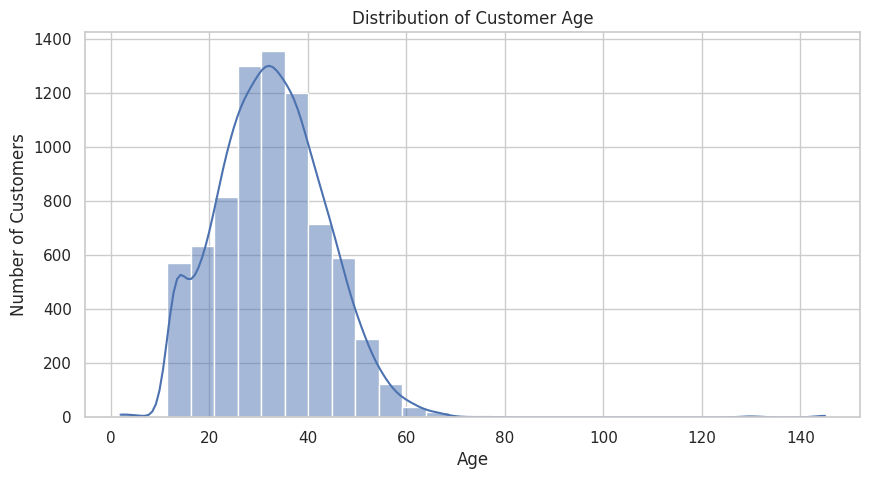

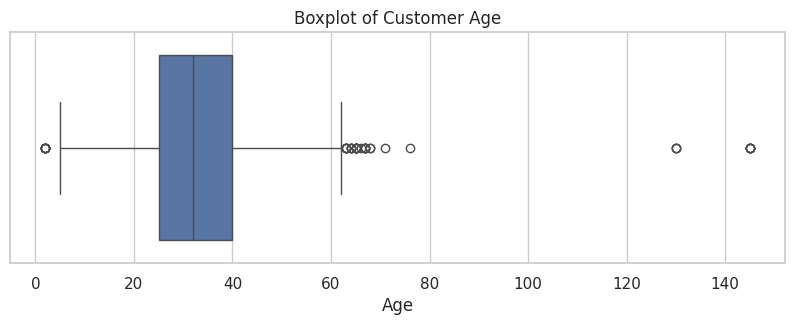

In [ ]:
# 2.9.1 AGE DISTRIBUTION ANALYSIS

customers_df = cleaned_datasets["Customers"]

age_data = customers_df["age"].dropna()

# Descriptive statistics
print("Age descriptive statistics:")

display(age_data.describe())

# Age distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    age_data,
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()


# Age boxplot
plt.figure(figsize=(10, 3))

sns.boxplot(x=age_data)

plt.title("Boxplot of Customer Age")
plt.xlabel("Age")

plt.show()

In [ ]:
# 2.9.2 IDENTIFY AGE OUTLIERS USING IQR

Q1 = age_data.quantile(0.25)

Q3 = age_data.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

age_outliers = age_data[
    (age_data < lower_bound) |
    (age_data > upper_bound)
]

print("First Quartile (Q1):", Q1)
print("Third Quartile (Q3):", Q3)
print("Interquartile Range (IQR):", IQR)

print("Lower IQR Bound:", lower_bound)
print("Upper IQR Bound:", upper_bound)

print("\nNumber of potential age outliers:",
      len(age_outliers))

print("\nPotential age outlier values:")

display(
    age_outliers.sort_values().to_frame(name="Age")
)

First Quartile (Q1): 25.0
Third Quartile (Q3): 40.0
Interquartile Range (IQR): 15.0
Lower IQR Bound: 2.5
Upper IQR Bound: 62.5

Number of potential age outliers: 43

Potential age outlier values:


,Age
1502,2.0
1543,2.0
3912,2.0
4870,2.0
5236,2.0
5674,2.0
4242,2.0
7628,2.0
1808,63.0
1475,63.0


### 2.9.3 Investigation of Extreme Age Values

The IQR analysis identified unusually low and high customer ages. These records require additional validation before any correction or removal.

The investigation focuses on:
- Customers aged below 13 years.
- Customers aged 100 years or older.
- Their customer IDs and available demographic information.
- The frequency of each extreme age value.

This step helps distinguish potentially incorrect entries from unusual but potentially valid customer records.

No age values will be modified during this investigation.

In [ ]:
# 2.9.3 INVESTIGATE EXTREME AGE RECORDS

customers_df = cleaned_datasets["Customers"]

# Display customers below 13 years or aged 100 and above
extreme_age_records = customers_df[
    (customers_df["age"] < 13) |
    (customers_df["age"] >= 100)
]

print("Number of extreme age records:",
      len(extreme_age_records))

print("\nExtreme age records:")

display(
    extreme_age_records[
        ["customer_id", "age", "country", "city",
         "gender", "customer_segment"]
    ].sort_values("age")
)

print("\nFrequency of extreme age values:")

display(
    extreme_age_records["age"]
    .value_counts()
    .sort_index()
    .to_frame(name="Customer Count")
)

Number of extreme age records: 21

Extreme age records:


,customer_id,age,country,city,gender,customer_segment
1502,CUST007699,2.0,India,Pune,Female,Individual
1543,CUST004926,2.0,United Kingdom,London,Female,Student
3912,CUST002247,2.0,NaN,Cordoba,Female,Individual
4242,CUST001630,2.0,South Korea,Seoul,Female,Student
5236,CUST004725,2.0,Philippines,Davao City,Male,Individual
5674,CUST001036,2.0,United States,Austin,Female,Corporate Bundle
4870,CUST001728,2.0,Indonesia,Bandung,Female,Family
7628,CUST007746,2.0,India,Kolkata,Male,Individual
6037,CUST004682,5.0,India,Ahmedabad,Female,Individual
4749,CUST003831,5.0,South Korea,Busan,Female,Individual



Frequency of extreme age values:


,Customer Count
age,
2.0,8
5.0,5
130.0,3
145.0,5


### 2.9.4 Treatment of Invalid Age Values

The investigation identified 21 customers with extreme age values.

Ages of 130 and 145 were considered implausible for customer demographic analysis. These values will be converted to missing values rather than deleting the corresponding customer records.

Customers aged 2 and 5 will be retained because the available data does not establish that these values are incorrect. However, they will be flagged for further validation.

Other statistically identified outliers, including ages between 63 and 76, will also be retained because older customers can be legitimate subscribers.

**Cleaning decision:**
- Convert ages of 130 and 145 to missing values.
- Retain ages of 2 and 5, with a validation flag.
- Retain other age outliers.
- Preserve all customer records.

This approach reduces the impact of implausible values while protecting potentially valid customer information.

In [ ]:
# 2.9.4 HANDLE INVALID AGE VALUES

customers_df = cleaned_datasets["Customers"]

# Count invalid ages before treatment
invalid_age_mask = customers_df["age"].isin([130, 145])

print("Invalid age records before treatment:",
      invalid_age_mask.sum())

# Convert implausible ages into missing values
customers_df.loc[invalid_age_mask, "age"] = np.nan

# Create a validation flag for unusually young customers
customers_df["age_validation_flag"] = np.where(
    customers_df["age"].isin([2, 5]),
    "Review Required",
    "No Flag"
)

# Display treatment results
print("\nInvalid ages converted to missing:",
      customers_df["age"].isna().sum())

print("\nAge validation flag distribution:")

display(
    customers_df["age_validation_flag"]
    .value_counts()
    .to_frame(name="Customer Count")
)

print("\nUpdated age statistics:")

display(customers_df["age"].describe())

print("\nCustomers with ages requiring review:")

display(
    customers_df.loc[
        customers_df["age_validation_flag"] == "Review Required",
        ["customer_id", "age", "country", "city"]
    ]
)

Invalid age records before treatment: 8

Invalid ages converted to missing: 329

Age validation flag distribution:


,Customer Count
age_validation_flag,
No Flag,7987
Review Required,13



Updated age statistics:


,age
count,7671.000000
mean,32.555469
std,10.754170
min,2.000000
25%,25.000000
50%,32.000000
75%,40.000000
max,76.000000



Customers with ages requiring review:


,customer_id,age,country,city
548,CUST007788,5.0,South Korea,Seoul
887,CUST001296,5.0,United Kingdom,London
1502,CUST007699,2.0,India,Pune
1543,CUST004926,2.0,United Kingdom,London
3912,CUST002247,2.0,NaN,Cordoba
4242,CUST001630,2.0,South Korea,Seoul
4749,CUST003831,5.0,South Korea,Busan
4870,CUST001728,2.0,Indonesia,Bandung
5236,CUST004725,2.0,Philippines,Davao City
5674,CUST001036,2.0,United States,Austin


In [ ]:
# VERIFY AGE CLEANING

customers_df = cleaned_datasets["Customers"]

print("Customers remaining:", len(customers_df))

print("\nMissing age values:",
      customers_df["age"].isna().sum())

print("\nAge validation flags:")

display(customers_df["age_validation_flag"].value_counts())

print("\nUpdated age distribution:")

display(customers_df["age"].describe())

Customers remaining: 8000

Missing age values: 329

Age validation flags:


,count
age_validation_flag,
No Flag,7987
Review Required,13



Updated age distribution:


,age
count,7671.000000
mean,32.555469
std,10.754170
min,2.000000
25%,25.000000
50%,32.000000
75%,40.000000
max,76.000000


### 2.10 Viewing Activity Data Validation

The Viewing Activity dataset contains customer-level streaming information, including watch duration, completion percentage, device type, viewing date, and session duration.

These attributes help measure customer engagement and understand viewing behaviour.

The validation focuses on:

1. Missing viewing information.
2. Negative or zero watch durations.
3. Unusually high watch durations.
4. Invalid completion percentages.
5. Unusually high session durations.

The objective is to identify data-quality problems while preserving legitimate viewing activity records.

In [ ]:
# 2.10.1 VIEWING ACTIVITY VALIDATION

viewing_df = cleaned_datasets["Viewing Activity"]

numeric_columns = [
    "watch_duration_minutes",
    "completion_percentage",
    "session_duration_minutes"
]

print("Numerical summary of viewing activity:")

display(viewing_df[numeric_columns].describe())

print("\nMissing values:")

display(viewing_df[numeric_columns].isna().sum().to_frame(
    name="Missing Values"
))

print("\nNegative values:")

for column in numeric_columns:
    print(
        column,
        ":",
        (viewing_df[column] < 0).sum()
    )

print("\nZero watch duration:",
      (viewing_df["watch_duration_minutes"] == 0).sum())

print("\nCompletion percentage outside 0-100:")

invalid_completion = viewing_df[
    (viewing_df["completion_percentage"] < 0) |
    (viewing_df["completion_percentage"] > 100)
]

print("Invalid records:", len(invalid_completion))

display(invalid_completion.head(10))

Numerical summary of viewing activity:


,watch_duration_minutes,completion_percentage,session_duration_minutes
count,66422.000000,65891.000000,66422.000000
mean,49.433862,70.474283,56.922285
std,40.388162,20.141997,40.800459
min,3.000000,1.000000,1.000000
25%,31.000000,57.000000,38.000000
50%,48.000000,71.000000,55.000000
75%,64.000000,86.000000,73.000000
max,894.000000,100.000000,907.000000



Missing values:


,Missing Values
watch_duration_minutes,0
completion_percentage,531
session_duration_minutes,0



Negative values:
watch_duration_minutes : 0
completion_percentage : 0
session_duration_minutes : 0

Zero watch duration: 0

Completion percentage outside 0-100:
Invalid records: 0


,viewing_id,customer_id,content_id,viewing_date,watch_duration_minutes,completion_percentage,device_type,login_location,session_duration_minutes


### 2.10.2 Investigation of Unusually High Viewing Durations

The descriptive statistics show that the maximum watch duration is 894 minutes and the maximum session duration is 907 minutes.

Although these values are considerably higher than the average viewing and session durations, they may represent unusually long sessions or potential recording errors.

We will inspect the records with the highest viewing and session durations and compare both measurements.

**Business objective:** Identify potentially abnormal viewing sessions without removing valid customer engagement records.

In [ ]:
# 2.10.2 INVESTIGATE HIGH VIEWING DURATIONS

viewing_df = cleaned_datasets["Viewing Activity"]

# Top 15 watch duration records
print("Top 15 longest watch durations:")

display(
    viewing_df.nlargest(
        15, "watch_duration_minutes"
    )[
        [
            "viewing_id",
            "customer_id",
            "content_id",
            "watch_duration_minutes",
            "completion_percentage",
            "session_duration_minutes",
            "device_type"
        ]
    ]
)

# Top 15 session duration records
print("\nTop 15 longest session durations:")

display(
    viewing_df.nlargest(
        15, "session_duration_minutes"
    )[
        [
            "viewing_id",
            "customer_id",
            "content_id",
            "watch_duration_minutes",
            "completion_percentage",
            "session_duration_minutes",
            "device_type"
        ]
    ]
)

Top 15 longest watch durations:


,viewing_id,customer_id,content_id,watch_duration_minutes,completion_percentage,session_duration_minutes,device_type
42156,VIEW00042157,CUST005069,CNT00463,894,78.0,897,Smart TV
50965,VIEW00050966,CUST006146,CNT00426,893,52.0,907,Mobile
47676,VIEW00047677,CUST005741,CNT00415,890,79.0,899,Laptop
61658,VIEW00061659,CUST007427,CNT00409,889,50.0,890,Mobile
22219,VIEW00022220,CUST002655,CNT00161,888,96.0,899,Mobile
8648,VIEW00008649,CUST001004,CNT00019,883,53.0,893,Mobile
36029,VIEW00036030,CUST004336,CNT00444,883,100.0,887,Gaming Console
11198,VIEW00011199,CUST001326,CNT00096,881,99.0,883,Desktop
28946,VIEW00028947,CUST003461,CNT00273,881,34.0,889,Smart TV
35535,VIEW00035536,CUST004276,CNT00096,879,100.0,878,Smart TV



Top 15 longest session durations:


,viewing_id,customer_id,content_id,watch_duration_minutes,completion_percentage,session_duration_minutes,device_type
50965,VIEW00050966,CUST006146,CNT00426,893,52.0,907,Mobile
22219,VIEW00022220,CUST002655,CNT00161,888,96.0,899,Mobile
47676,VIEW00047677,CUST005741,CNT00415,890,79.0,899,Laptop
42156,VIEW00042157,CUST005069,CNT00463,894,78.0,897,Smart TV
8648,VIEW00008649,CUST001004,CNT00019,883,53.0,893,Mobile
61658,VIEW00061659,CUST007427,CNT00409,889,50.0,890,Mobile
28946,VIEW00028947,CUST003461,CNT00273,881,34.0,889,Smart TV
36029,VIEW00036030,CUST004336,CNT00444,883,100.0,887,Gaming Console
60016,VIEW00060017,CUST007238,CNT00364,879,85.0,884,Mobile
11198,VIEW00011199,CUST001326,CNT00096,881,99.0,883,Desktop


### 2.10.2 Findings – Unusually High Viewing Durations

The investigation examined the 15 longest watch durations and the 15 longest session durations.

The results showed:
- Maximum watch duration: 894 minutes.
- Maximum session duration: 907 minutes.
- Long-duration records were observed across multiple device types.
- Watch duration and session duration were generally close to each other.
- Completion percentages remained within the valid range of 0–100%.

Although these durations are unusually high, the available information does not establish that they are incorrect.

**Business decision:** Retain all viewing records without deleting or capping unusually high durations. Further analysis can use these values when studying customer engagement.

In [ ]:
# 2.10.3 VALIDATE WATCH AND SESSION DURATION

viewing_df = cleaned_datasets["Viewing Activity"]

# Records where watch duration exceeds session duration
duration_mismatch = viewing_df[
    viewing_df["watch_duration_minutes"] >
    viewing_df["session_duration_minutes"]
]

print("Records where watch duration exceeds session duration:",
      len(duration_mismatch))

print("\nSample mismatched records:")

display(
    duration_mismatch[
        [
            "viewing_id",
            "customer_id",
            "watch_duration_minutes",
            "session_duration_minutes",
            "completion_percentage"
        ]
    ].head(15)
)

# Difference between session and watch duration
viewing_df["session_watch_gap"] = (
    viewing_df["session_duration_minutes"] -
    viewing_df["watch_duration_minutes"]
)

print("\nSession-watch duration gap statistics:")

display(viewing_df["session_watch_gap"].describe())

Records where watch duration exceeds session duration: 6079

Sample mismatched records:


,viewing_id,customer_id,watch_duration_minutes,session_duration_minutes,completion_percentage
10,VIEW00000011,CUST000003,81,80,80.0
17,VIEW00000018,CUST000004,52,50,38.0
43,VIEW00000044,CUST000007,94,93,83.0
44,VIEW00000045,CUST000007,41,40,77.0
47,VIEW00000048,CUST000008,46,43,100.0
79,VIEW00000080,CUST000011,92,90,51.0
80,VIEW00000081,CUST000011,25,24,84.0
98,VIEW00000099,CUST000014,28,23,61.0
120,VIEW00000121,CUST000018,55,54,100.0
128,VIEW00000129,CUST000019,9,7,94.0



Session-watch duration gap statistics:


,session_watch_gap
count,66422.000000
mean,7.488423
std,5.951143
min,-19.000000
25%,3.000000
50%,7.000000
75%,12.000000
max,32.000000


### 2.10.3 Watch Duration and Session Duration Consistency Check

A consistency check was performed to compare watch duration with session duration.

The analysis identified 6,079 records (approximately 9.15% of all viewing records) where watch duration exceeded session duration.

The session-watch gap was calculated as:

Session-Watch Gap = Session Duration − Watch Duration

The results showed:
- Average gap: 7.49 minutes.
- Median gap: 7 minutes.
- Minimum gap: -19 minutes.
- Maximum gap: 32 minutes.

A negative gap indicates that the recorded watch duration is greater than the recorded session duration.

**Business decision:**

These records will be retained without modifying either duration. The available data does not establish which measurement is incorrect. The inconsistency will be documented as a data-quality limitation and considered during feature engineering and analysis.

In [ ]:
# 2.10.4 ANALYSE DURATION MISMATCH SEVERITY

viewing_df = cleaned_datasets["Viewing Activity"]

# Separate negative and non-negative gaps
negative_gaps = viewing_df[
    viewing_df["session_watch_gap"] < 0
]

print("Negative gap records:", len(negative_gaps))

print("\nNegative gap statistics:")

display(negative_gaps["session_watch_gap"].describe())

# Categorise mismatch severity
viewing_df["duration_mismatch_category"] = np.select(
    [
        viewing_df["session_watch_gap"] >= 0,
        viewing_df["session_watch_gap"] >= -5,
        viewing_df["session_watch_gap"] >= -10,
        viewing_df["session_watch_gap"] < -10
    ],
    [
        "No Mismatch",
        "Small Mismatch (1-5 min)",
        "Moderate Mismatch (6-10 min)",
        "Large Mismatch (More than 10 min)"
    ],
    default="Unknown"
)

print("\nDuration mismatch categories:")

display(
    viewing_df["duration_mismatch_category"]
    .value_counts()
    .to_frame(name="Record Count")
)

Negative gap records: 6079

Negative gap statistics:


,session_watch_gap
count,6079.000000
mean,-3.188189
std,2.363785
min,-19.000000
25%,-4.000000
50%,-2.000000
75%,-1.000000
max,-1.000000



Duration mismatch categories:


,Record Count
duration_mismatch_category,
No Mismatch,60343
Small Mismatch (1-5 min),5178
Moderate Mismatch (6-10 min),822
Large Mismatch (More than 10 min),79


### 2.10.4 Duration Mismatch Severity Analysis

The duration mismatch analysis classified viewing records according to the difference between session duration and watch duration.

| Category | Record Count |
|---|---:|
| No Mismatch | 60,343 |
| Small Mismatch (1–5 minutes) | 5,178 |
| Moderate Mismatch (6–10 minutes) | 822 |
| Large Mismatch (More than 10 minutes) | 79 |

Among the 6,079 records where watch duration exceeded session duration:
- 5,178 records had a small mismatch.
- 822 records had a moderate mismatch.
- 79 records had a large mismatch.

The average negative duration gap was approximately 3.19 minutes.

**Business decision:** Retain all records without modifying the original duration columns. The mismatch category is retained as a diagnostic field for further data-quality analysis.

### 2.10.5 Investigation of Missing Completion Percentages

The Viewing Activity dataset contains 531 missing values in the completion_percentage column.

Completion percentage measures how much of a content item a customer watched.

Before selecting a treatment strategy, we will investigate:
- The number of records with missing completion percentages.
- Their watch-duration distribution.
- Their session-duration distribution.
- Whether missing completion values are associated with particular devices.

Missing values will not be automatically replaced with zero because an unknown completion percentage does not necessarily indicate that the customer watched none of the content.

In [ ]:
# 2.10.5 INVESTIGATE MISSING COMPLETION PERCENTAGES

viewing_df = cleaned_datasets["Viewing Activity"]

missing_completion = viewing_df[
    viewing_df["completion_percentage"].isna()
]

print("Records with missing completion percentage:",
      len(missing_completion))

print("\nWatch duration statistics for missing records:")

display(
    missing_completion["watch_duration_minutes"].describe()
)

print("\nSession duration statistics for missing records:")

display(
    missing_completion["session_duration_minutes"].describe()
)

print("\nMissing completion percentage by device:")

display(
    missing_completion["device_type"]
    .value_counts(dropna=False)
    .to_frame(name="Missing Records")
)

print("\nComparison of average durations:")

comparison = pd.DataFrame({
    "Missing Completion": missing_completion[
        ["watch_duration_minutes", "session_duration_minutes"]
    ].mean(),

    "Available Completion": viewing_df.loc[
        viewing_df["completion_percentage"].notna(),
        ["watch_duration_minutes", "session_duration_minutes"]
    ].mean()
})

display(comparison)

Records with missing completion percentage: 531

Watch duration statistics for missing records:


,watch_duration_minutes
count,531.000000
mean,47.824859
std,32.044448
min,3.000000
25%,29.500000
50%,46.000000
75%,64.000000
max,546.000000



Session duration statistics for missing records:


,session_duration_minutes
count,531.000000
mean,55.124294
std,32.566153
min,1.000000
25%,37.000000
50%,53.000000
75%,71.000000
max,552.000000



Missing completion percentage by device:


,Missing Records
device_type,
Smart TV,190
Mobile,167
Tablet,68
Laptop,56
Gaming Console,35
NaN,8
Desktop,7



Comparison of average durations:


,Missing Completion,Available Completion
watch_duration_minutes,47.824859,49.446829
session_duration_minutes,55.124294,56.936774


### 2.10.5 Findings – Missing Completion Percentages

The investigation identified 531 missing values in the completion_percentage column.

The average viewing durations were compared between records with missing and available completion percentages.

| Measurement | Missing Completion | Available Completion |
|---|---:|---:|
| Average Watch Duration | 47.82 minutes | 49.45 minutes |
| Average Session Duration | 55.12 minutes | 56.94 minutes |

Device-level analysis showed that Smart TV had the highest number of missing completion values (190), followed by Mobile (167).

The viewing-duration averages were relatively similar between the two groups.

**Business decision:**

- Retain all viewing records.
- Do not replace missing completion percentages with zero or arbitrary averages.
- Preserve missing values for descriptive analysis.
- Apply appropriate imputation only when required by a machine-learning pipeline, using training data to avoid data leakage.

This approach preserves the original viewing information without introducing unsupported assumptions.

### 2.10.6 Final Viewing Activity Validation Summary

The Viewing Activity dataset was examined for missing values, invalid numerical values, unusually high durations, and inconsistencies between watch duration and session duration.

The following decisions were made:

| Validation Area | Finding | Treatment |
|---|---|---|
| Watch Duration | No missing, negative, or zero values | Retained |
| Completion Percentage | 531 missing values | Preserved as missing |
| Completion Range | All available values within 0–100 | Retained |
| Session Duration | No missing or negative values | Retained |
| Long Viewing Sessions | Unusually high durations identified | Retained |
| Duration Consistency | 6,079 records have watch duration greater than session duration | Retained and documented |
| Device Type | Inconsistent naming standardised in an earlier step | Standardised |

No viewing records were deleted during this validation process.

The dataset retains its original viewing measurements, along with diagnostic fields created during investigation.

**Conclusion:** The Viewing Activity dataset is ready for further analysis, with the identified data-quality limitations documented.

### 2.11 Support Tickets Data Validation

The Support Tickets dataset contains customer service interactions, including issue categories, ticket status, resolution time, customer satisfaction scores, and support agent information.

This dataset is important for understanding customer complaints, service quality, and potential factors contributing to customer churn.

The validation focuses on:
1. Missing resolution times and satisfaction scores.
2. Negative or unusually high resolution times.
3. Invalid customer satisfaction scores.
4. Ticket status and issue category consistency.

The objective is to preserve meaningful support records while identifying potential data-quality problems.

In [ ]:
# 2.11.1 SUPPORT TICKETS DATA VALIDATION

support_df = cleaned_datasets["Support Tickets"]

print("Support Tickets Dataset Shape:", support_df.shape)

print("\nNumerical Summary:")

display(
    support_df[
        ["resolution_time_hours", "customer_satisfaction_score"]
    ].describe()
)

print("\nMissing Values:")

display(support_df.isna().sum().to_frame(
    name="Missing Values"
))

print("\nTicket Status Distribution:")

display(
    support_df["ticket_status"]
    .value_counts()
    .to_frame(name="Ticket Count")
)

print("\nIssue Category Distribution:")

display(
    support_df["issue_category"]
    .value_counts()
    .to_frame(name="Ticket Count")
)

Support Tickets Dataset Shape: (6120, 11)

Numerical Summary:


,resolution_time_hours,customer_satisfaction_score
count,4592.000000,4592.000000
mean,17.998911,3.258493
std,17.689077,1.107013
min,0.500000,1.000000
25%,5.200000,3.000000
50%,12.700000,3.000000
75%,25.000000,4.000000
max,151.100000,5.000000



Missing Values:


,Missing Values
ticket_id,0
customer_id,0
ticket_date,61
issue_category,0
issue_subcategory,0
priority,0
ticket_status,0
resolution_time_hours,1528
customer_satisfaction_score,1528
ticket_description,0



Ticket Status Distribution:


,Ticket Count
ticket_status,
Resolved,3390
Closed,1202
Pending,888
Escalated,640



Issue Category Distribution:


,Ticket Count
issue_category,
Billing & Payments,1709
Streaming Quality,1323
Account Access,998
Subscription,881
Device & App,738
Content,471


#### 2.11.2 Resolution Time and Satisfaction Score Validation

Resolution time and customer satisfaction are important indicators of customer support performance.

Resolution time is expected to be a positive numerical value. Negative or zero values would require investigation. Longer resolution times may represent complex customer issues and should not automatically be treated as errors.

Customer satisfaction scores are expected to follow a 1–5 rating scale.

This validation checks for:
- Negative or zero resolution times.
- Unusually high resolution times.
- Satisfaction scores outside the valid 1–5 range.
- Missing values that were previously identified as belonging to unresolved tickets.

In [ ]:
# 2.11.2 Validate Resolution Time and Satisfaction Scores

# Check invalid resolution times
invalid_resolution = support_df[
    support_df["resolution_time_hours"] <= 0
]

# Check unusually high resolution times
high_resolution = support_df[
    support_df["resolution_time_hours"] > 72
]

# Check invalid satisfaction scores
invalid_satisfaction = support_df[
    ~support_df["customer_satisfaction_score"].between(1, 5)
    & support_df["customer_satisfaction_score"].notna()
]

print("Invalid Resolution Times:", len(invalid_resolution))
print("Resolution Times Above 72 Hours:", len(high_resolution))
print("Invalid Satisfaction Scores:", len(invalid_satisfaction))

print("\nHigh Resolution Time Records:")
display(
    high_resolution[
        ["ticket_id", "issue_category", "priority",
         "ticket_status", "resolution_time_hours"]
    ].head(10)
)

print("\nInvalid Satisfaction Score Records:")
display(
    invalid_satisfaction[
        ["ticket_id", "customer_satisfaction_score"]
    ].head(10)
)

Invalid Resolution Times: 0
Resolution Times Above 72 Hours: 72
Invalid Satisfaction Scores: 0

High Resolution Time Records:


,ticket_id,issue_category,priority,ticket_status,resolution_time_hours
93,TCK0000094,Subscription,High,Resolved,78.6
120,TCK0000121,Billing & Payments,Medium,Resolved,85.2
247,TCK0000248,Content,High,Resolved,151.1
321,TCK0000322,Streaming Quality,Low,Resolved,81.4
332,TCK0000333,Account Access,Critical,Closed,93.4
360,TCK0000361,Account Access,Critical,Closed,103.9
368,TCK0000369,Billing & Payments,Medium,Closed,82.9
393,TCK0000394,Billing & Payments,Critical,Closed,77.4
417,TCK0000418,Subscription,Low,Resolved,99.0
452,TCK0000453,Billing & Payments,Medium,Closed,89.6



Invalid Satisfaction Score Records:


,ticket_id,customer_satisfaction_score


#### 2.11.3 Support Tickets – Validation Findings and Cleaning Decisions

The validation identified 72 support tickets with resolution times exceeding 72 hours. These values were investigated as potentially unusual observations. Since they are positive values and no evidence of incorrect records was identified, they will be retained.

The validation also confirmed:
- No negative or zero resolution times were found.
- No customer satisfaction scores outside the 1–5 range were found.
- Missing resolution times and satisfaction scores belong to Pending and Escalated tickets.
- Invalid ticket dates were converted to missing datetime values, while the original ticket records were preserved.

**Cleaning decisions:**
- Retain all 6,120 support ticket records.
- Preserve missing resolution times and satisfaction scores.
- Retain unusually long resolution times.
- Keep valid satisfaction scores unchanged.
- Preserve invalid ticket dates as missing values rather than inventing replacement dates.

In [ ]:
# 2.11.3 Validate Support Ticket Categorical Columns

categorical_columns = [
    "issue_category",
    "issue_subcategory",
    "priority",
    "ticket_status"
]

for column in categorical_columns:
    print(f"\n{column} - Unique Values:")
    print(sorted(support_df[column].dropna().unique()))

    print(f"\n{column} - Value Counts:")
    display(support_df[column].value_counts().to_frame(
        name="Count"
    ))


issue_category - Unique Values:
['Account Access', 'Billing & Payments', 'Content', 'Device & App', 'Streaming Quality', 'Subscription']

issue_category - Value Counts:


,Count
issue_category,
Billing & Payments,1709
Streaming Quality,1323
Account Access,998
Subscription,881
Device & App,738
Content,471



issue_subcategory - Unique Values:
['Account locked', 'App crashing', 'App not loading', 'Audio sync issue', 'Auto-renew complaint', 'Buffering', 'Cancellation request', 'Content removed', 'Content unavailable in region', 'Device not supported', 'Download failure', 'Duplicate charge', 'Email verification issue', 'Failed payment', 'Invoice question', 'Login failure', 'Low resolution', 'Missing subtitles', 'Password reset', 'Plan downgrade request', 'Plan upgrade request', 'Price dispute', 'Refund request', 'Sync across devices']

issue_subcategory - Value Counts:


,Count
issue_subcategory,
Invoice question,373
Refund request,366
Buffering,356
Failed payment,350
Audio sync issue,336
App crashing,332
Duplicate charge,314
Price dispute,306
Low resolution,299



priority - Unique Values:
['Critical', 'High', 'Low', 'Medium']

priority - Value Counts:


,Count
priority,
Low,2204
Medium,2087
High,1328
Critical,501



ticket_status - Unique Values:
['Closed', 'Escalated', 'Pending', 'Resolved']

ticket_status - Value Counts:


,Count
ticket_status,
Resolved,3390
Closed,1202
Pending,888
Escalated,640


#### 2.11.4 Final Support Tickets Cleaning Summary

The Support Tickets dataset was successfully validated.

The following observations and cleaning decisions were recorded:

| Validation | Finding | Decision |
|---|---|---|
| Duplicate records | No duplicates | No removal required |
| Invalid ticket dates | 61 records | Retained with missing dates |
| Missing resolution times | 1,528 | Preserved |
| Missing satisfaction scores | 1,528 | Preserved |
| Invalid resolution times | None | No correction required |
| Resolution times above 72 hours | 72 | Retained |
| Invalid satisfaction scores | None | No correction required |
| Categorical values | Consistent | No standardisation required |

All 6,120 support ticket records were retained.

Missing resolution and satisfaction values were preserved because they correspond to Pending and Escalated tickets. Unusually long resolution times were also retained because they may represent genuine customer support cases.

The dataset is now ready for further integration and analysis.

### 2.12 Payments Data Validation

The Payments dataset contains customer transaction information, including payment dates, transaction amounts, payment methods, payment statuses, and failed payment reasons.

Payment information is important for analysing revenue, transaction failures, payment behaviour, and possible financial factors associated with customer churn.

The validation will focus on:
1. Missing payment information.
2. Positive and valid transaction amounts.
3. Payment status and payment method consistency.
4. Failed payment reasons.
5. Unusually high or low transaction amounts.

The completely empty `subscription_id` column was already removed during preprocessing. Payments will later be associated with subscriptions using customer IDs and payment dates, where the subscription date range supports a reliable match.

In [ ]:
# 2.12.1 PAYMENTS DATA OVERVIEW

payments_df = cleaned_datasets["Payments"]

print("Payments Dataset Shape:", payments_df.shape)

print("\nNumerical Summary:")

display(payments_df[["amount"]].describe())

print("\nMissing Values:")

display(
    payments_df.isna().sum().to_frame(
        name="Missing Values"
    )
)

print("\nPayment Status Distribution:")

display(
    payments_df["payment_status"]
    .value_counts()
    .to_frame(name="Transaction Count")
)

print("\nPayment Method Distribution:")

display(
    payments_df["payment_method"]
    .value_counts()
    .to_frame(name="Transaction Count")
)

print("\nFailed Payment Reason Distribution:")

display(
    payments_df["failed_payment_reason"]
    .value_counts()
    .to_frame(name="Transaction Count")
)

Payments Dataset Shape: (110735, 7)

Numerical Summary:


,amount
count,110735.000000
mean,13.750196
std,9.510979
min,0.000000
25%,6.990000
50%,15.490000
75%,15.490000
max,252.890000



Missing Values:


,Missing Values
payment_id,0
customer_id,0
payment_date,0
amount,0
payment_method,0
payment_status,0
failed_payment_reason,103529



Payment Status Distribution:


,Transaction Count
payment_status,
Success,103529
Failed,7206



Payment Method Distribution:


,Transaction Count
payment_method,
Credit Card,33249
Debit Card,19751
UPI,17730
PayPal,13375
Net Banking,11344
Mobile Wallet,8697
Gift Card,6589



Failed Payment Reason Distribution:


,Transaction Count
failed_payment_reason,
Bank declined,1278
Card expired,1211
Incorrect card details,1198
Insufficient funds,1189
Card reported lost/stolen,1180
International transaction blocked,1150


#### 2.12.2 Payment Amount Validation

Transaction amounts are important for revenue analysis and payment behaviour monitoring.

The initial numerical summary shows transaction amounts ranging from 0.00 to 252.89, with an average amount of approximately 13.75.

Zero-value transactions and unusually high amounts require investigation before deciding whether they represent errors or legitimate payment records.

This validation checks:
- Zero-value transactions.
- Negative transaction amounts.
- Unusually high transaction amounts.
- Payment status associated with zero-value transactions.

No transactions will be removed solely because their amounts appear unusual.

In [ ]:
# 2.12.2 Validate Payment Amounts

# Identify zero-value transactions
zero_payments = payments_df[
    payments_df["amount"] == 0
]

# Identify negative transaction amounts
negative_payments = payments_df[
    payments_df["amount"] < 0
]

# Identify unusually high amounts using the IQR method
Q1 = payments_df["amount"].quantile(0.25)
Q3 = payments_df["amount"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + (1.5 * IQR)

high_amount_payments = payments_df[
    payments_df["amount"] > upper_limit
]

print("Zero-Value Transactions:", len(zero_payments))
print("Negative Transactions:", len(negative_payments))
print("Upper IQR Limit:", upper_limit)
print("Unusually High Transactions:", len(high_amount_payments))

print("\nZero-Value Transaction Status:")

display(
    zero_payments["payment_status"]
    .value_counts()
    .to_frame(name="Transaction Count")
)

print("\nSample Zero-Value Transactions:")

display(zero_payments.head(10))

print("\nSample High-Value Transactions:")

display(
    high_amount_payments[
        ["payment_id", "customer_id", "payment_date",
         "amount", "payment_status", "payment_method"]
    ].head(10)
)

Zero-Value Transactions: 250
Negative Transactions: 0
Upper IQR Limit: 28.240000000000002
Unusually High Transactions: 463

Zero-Value Transaction Status:


,Transaction Count
payment_status,
Success,239
Failed,11



Sample Zero-Value Transactions:


,payment_id,customer_id,payment_date,amount,payment_method,payment_status,failed_payment_reason
111,PAY00000112,CUST000009,2020-10-13,0.0,UPI,Success,NaN
905,PAY00000906,CUST000068,2022-02-02,0.0,UPI,Success,NaN
1306,PAY00001307,CUST000098,2021-04-24,0.0,Credit Card,Success,NaN
1639,PAY00001640,CUST000122,2021-06-09,0.0,Credit Card,Success,NaN
1807,PAY00001808,CUST000135,2021-10-23,0.0,Gift Card,Success,NaN
2102,PAY00002103,CUST000157,2022-10-11,0.0,Gift Card,Success,NaN
2708,PAY00002709,CUST000202,2020-04-21,0.0,Mobile Wallet,Success,NaN
2725,PAY00002726,CUST000203,2021-05-12,0.0,Gift Card,Success,NaN
2790,PAY00002791,CUST000209,2026-02-01,0.0,UPI,Success,NaN
3578,PAY00003579,CUST000266,2026-03-28,0.0,Debit Card,Success,NaN



Sample High-Value Transactions:


,payment_id,customer_id,payment_date,amount,payment_status,payment_method
71,PAY00000072,CUST000006,2025-12-16,252.89,Success,UPI
95,PAY00000096,CUST000008,2024-06-16,170.39,Success,Credit Card
640,PAY00000641,CUST000050,2020-10-28,170.39,Success,Debit Card
700,PAY00000701,CUST000054,2023-10-29,252.89,Success,Mobile Wallet
1240,PAY00001241,CUST000092,2026-04-12,76.89,Success,Mobile Wallet
1710,PAY00001711,CUST000127,2021-10-04,78.17,Success,Debit Card
1714,PAY00001715,CUST000127,2022-02-01,78.17,Success,Net Banking
2053,PAY00002054,CUST000154,2021-12-24,52.67,Success,Debit Card
2169,PAY00002170,CUST000162,2020-08-16,30.98,Success,PayPal
2257,PAY00002258,CUST000168,2025-07-13,170.39,Success,Mobile Wallet


#### 2.12.3 Investigation of Zero-Value Transactions

The payment validation identified 250 transactions with an amount of zero.

Among these:
- 239 transactions have a Successful payment status.
- 11 transactions have a Failed payment status.

Zero-value transactions may represent promotional payments, gift-card adjustments, free subscription periods, or possible data-entry issues.

Since the dataset does not provide enough information to identify the exact reason for every zero-value transaction, these records will be investigated further before deciding their treatment.

The transactions will not be deleted or replaced with arbitrary amounts.

In [ ]:
# 2.12.3 Investigate Zero-Value Transactions

print("Zero-Value Transactions by Payment Method:")

display(
    zero_payments.groupby(
        ["payment_method", "payment_status"]
    ).size().unstack(fill_value=0)
)

print("\nZero-Value Transactions by Year:")

zero_payments["payment_year"] = (
    zero_payments["payment_date"].dt.year
)

display(
    zero_payments.groupby(
        ["payment_year", "payment_status"]
    ).size().unstack(fill_value=0)
)

print("\nZero-Value Transactions by Customer:")

display(
    zero_payments["customer_id"]
    .value_counts()
    .head(10)
    .to_frame(name="Zero-Value Transaction Count")
)

Zero-Value Transactions by Payment Method:


payment_status,Failed,Success
payment_method,,
Credit Card,3,70
Debit Card,3,46
Gift Card,1,11
Mobile Wallet,0,22
Net Banking,0,21
PayPal,2,22
UPI,2,47



Zero-Value Transactions by Year:


payment_status,Failed,Success
payment_year,,
2019,0,14
2020,3,39
2021,0,37
2022,2,34
2023,5,36
2024,0,27
2025,1,36
2026,0,16



Zero-Value Transactions by Customer:


,Zero-Value Transaction Count
customer_id,
CUST000651,2
CUST001612,2
CUST003145,2
CUST005111,2
CUST000098,1
CUST000122,1
CUST000157,1
CUST000202,1
CUST000209,1


#### 2.12.4 Zero-Value and High-Value Payment Investigation – Findings

The investigation identified 250 zero-value transactions across all seven payment methods and multiple years.

Of these:
- 239 transactions were marked Successful.
- 11 transactions were marked Failed.
- Zero-value transactions occurred between 2019 and 2026.
- Four customers had two zero-value transactions each.

The available dataset does not provide sufficient information to establish why successful transactions have zero amounts. Therefore, these transactions will be retained without modification.

The IQR method also identified 463 unusually high-value transactions. These observations will be retained because statistical outliers are not necessarily incorrect financial records.

**Final decision:**
- Retain all zero-value transactions.
- Retain all high-value transactions.
- Do not modify or remove negative amounts; none were found.
- Preserve the original payment amounts for accurate financial analysis.

In [ ]:
# 2.12.5 Validate Payment Categories

categorical_columns = [
    "payment_method",
    "payment_status",
    "failed_payment_reason"
]

for column in categorical_columns:

    print(f"\n{column} - Unique Values:")

    print(
        sorted(payments_df[column].dropna().unique())
    )

    print(f"\n{column} - Value Counts:")

    display(
        payments_df[column]
        .value_counts()
        .to_frame(name="Count")
    )

# Check failed payment reasons against payment status

print("\nFailed Payment Reason by Payment Status:")

display(
    payments_df.groupby(
        "payment_status"
    )["failed_payment_reason"]
    .apply(lambda x: x.notna().sum())
    .to_frame(name="Available Failure Reasons")
)


payment_method - Unique Values:
['Credit Card', 'Debit Card', 'Gift Card', 'Mobile Wallet', 'Net Banking', 'PayPal', 'UPI']

payment_method - Value Counts:


,Count
payment_method,
Credit Card,33249
Debit Card,19751
UPI,17730
PayPal,13375
Net Banking,11344
Mobile Wallet,8697
Gift Card,6589



payment_status - Unique Values:
['Failed', 'Success']

payment_status - Value Counts:


,Count
payment_status,
Success,103529
Failed,7206



failed_payment_reason - Unique Values:
['Bank declined', 'Card expired', 'Card reported lost/stolen', 'Incorrect card details', 'Insufficient funds', 'International transaction blocked']

failed_payment_reason - Value Counts:


,Count
failed_payment_reason,
Bank declined,1278
Card expired,1211
Incorrect card details,1198
Insufficient funds,1189
Card reported lost/stolen,1180
International transaction blocked,1150



Failed Payment Reason by Payment Status:


,Available Failure Reasons
payment_status,
Failed,7206
Success,0


#### 2.12.6 Final Payments Data Cleaning Summary

The Payments dataset was successfully validated.

| Validation | Finding | Decision |
|---|---|---|
| Duplicate transactions | None | No removal required |
| Missing payment amounts | None | No correction required |
| Negative amounts | None | No correction required |
| Zero-value transactions | 250 | Retained |
| High-value transactions | 463 | Retained |
| Successful transactions | 103,529 | Valid |
| Failed transactions | 7,206 | Valid |
| Missing failure reasons | 103,529 | Expected for successful payments |
| Failed transactions with reasons | 7,206 | Complete |
| Payment categories | Consistent | No standardisation required |
| Empty subscription ID column | Removed | No direct subscription key available |

All 110,735 payment records were retained.

Zero-value and unusually high-value transactions were preserved because the available information does not establish that they are incorrect.

Missing failed payment reasons were considered expected for successful transactions.

The Payments dataset is ready for further analysis and integration with customer and subscription information.

### 2.13 Subscriptions Data Validation

The Subscriptions dataset contains customer subscription records, including subscription IDs, customer IDs, plan information, start and end dates, subscription status, auto-renewal settings, cancellation information, and monthly prices.

This dataset is important for understanding customer subscription behaviour, plan changes, cancellations, subscription duration, and revenue patterns.

The validation will focus on:
1. Missing subscription end dates and cancellation information.
2. Subscription status consistency.
3. Subscription date validity.
4. Monthly price validation.
5. Multiple subscriptions associated with the same customer.

Multiple subscriptions for one customer are valid because customers may change or upgrade their subscription plans. Therefore, repeated customer IDs will not be treated as duplicates.

In [ ]:
# 2.13.1 SUBSCRIPTIONS DATA OVERVIEW

subscriptions_df = cleaned_datasets["Subscriptions"]

print("Subscriptions Dataset Shape:", subscriptions_df.shape)

print("\nNumerical Summary:")

display(
    subscriptions_df[["monthly_price"]].describe()
)

print("\nMissing Values:")

display(
    subscriptions_df.isna().sum().to_frame(
        name="Missing Values"
    )
)

print("\nSubscription Status Distribution:")

display(
    subscriptions_df["subscription_status"]
    .value_counts()
    .to_frame(name="Subscription Count")
)

print("\nSubscription Plan Distribution:")

display(
    subscriptions_df["plan_id"]
    .value_counts()
    .to_frame(name="Subscription Count")
)

print("\nAuto-Renew Distribution:")

display(
    subscriptions_df["auto_renew"]
    .value_counts()
    .to_frame(name="Subscription Count")
)

Subscriptions Dataset Shape: (8875, 10)

Numerical Summary:


,monthly_price
count,8875.000000
mean,13.450676
std,6.139500
min,6.990000
25%,6.990000
50%,15.490000
75%,15.490000
max,22.990000



Missing Values:


,Missing Values
subscription_id,0
customer_id,0
plan_id,0
subscription_start_date,0
subscription_end_date,8000
subscription_status,0
auto_renew,0
cancellation_date,6884
cancellation_reason,6884
monthly_price,0



Subscription Status Distribution:


,Subscription Count
subscription_status,
Active,6009
Cancelled,1991
Plan Changed,875



Subscription Plan Distribution:


,Subscription Count
plan_id,
PLAN01,3671
PLAN02,3301
PLAN03,1903



Auto-Renew Distribution:


,Subscription Count
auto_renew,
True,7227
False,1648


#### 2.13.2 Investigation of Missing Subscription Dates

The Subscriptions dataset contains missing values in three columns:

- subscription_end_date: 8,000 missing values
- cancellation_date: 6,884 missing values
- cancellation_reason: 6,884 missing values

These missing values may be valid depending on the subscription status. For example, an active subscription may not have an end date or cancellation information.

To verify this, missing values will be compared against subscription statuses. This will help determine whether the missing information represents normal business activity or requires further investigation.

In [ ]:
# 2.13.2 Investigate Missing Subscription Information

missing_by_status = subscriptions_df.groupby(
    "subscription_status"
).agg(
    Total_Records=("subscription_id", "count"),
    Missing_End_Date=("subscription_end_date", lambda x: x.isna().sum()),
    Missing_Cancellation_Date=("cancellation_date", lambda x: x.isna().sum()),
    Missing_Cancellation_Reason=("cancellation_reason", lambda x: x.isna().sum())
)

display(missing_by_status)

,Total_Records,Missing_End_Date,Missing_Cancellation_Date,Missing_Cancellation_Reason
subscription_status,,,,
Active,6009,6009,6009,6009
Cancelled,1991,1991,0,0
Plan Changed,875,0,875,875


#### 2.13.3 Investigation of Cancelled Subscription End Dates

The missing-value analysis revealed that all 1,991 cancelled subscription records have missing subscription end dates, even though their cancellation dates and cancellation reasons are available.

This requires further investigation because cancellation dates may help explain when a subscription ended.

The following checks will be performed:
- Compare subscription start dates with cancellation dates.
- Check whether cancellation dates occur after subscription start dates.
- Inspect sample cancelled subscription records.
- Determine whether the missing end dates can be understood from the available cancellation information.

No values will be filled or modified without sufficient business evidence.

In [ ]:
# 2.13.3 Investigate Cancelled Subscription End Dates

cancelled_subscriptions = subscriptions_df[
    subscriptions_df["subscription_status"] == "Cancelled"
].copy()

print("Cancelled Subscription Records:", len(cancelled_subscriptions))

print("\nMissing End Dates:")
print(cancelled_subscriptions["subscription_end_date"].isna().sum())

print("\nMissing Cancellation Dates:")
print(cancelled_subscriptions["cancellation_date"].isna().sum())

print("\nMissing Cancellation Reasons:")
print(cancelled_subscriptions["cancellation_reason"].isna().sum())

print("\nSample Cancelled Subscription Records:")

display(
    cancelled_subscriptions[
        [
            "subscription_id",
            "customer_id",
            "subscription_start_date",
            "subscription_end_date",
            "cancellation_date",
            "cancellation_reason",
            "monthly_price"
        ]
    ].head(10)
)

Cancelled Subscription Records: 1991

Missing End Dates:
1991

Missing Cancellation Dates:
0

Missing Cancellation Reasons:
0

Sample Cancelled Subscription Records:


,subscription_id,customer_id,subscription_start_date,subscription_end_date,cancellation_date,cancellation_reason,monthly_price
2,SUB0000003,CUST000003,2019-12-15,NaT,2026-04-20,Too expensive,22.99
6,SUB0000007,CUST000007,2025-10-30,NaT,2026-05-05,Password sharing crackdown,15.49
13,SUB0000014,CUST000014,2025-10-13,NaT,2026-01-31,Too expensive,15.49
22,SUB0000023,CUST000023,2026-04-13,NaT,2026-06-05,No longer needed,15.49
24,SUB0000025,CUST000025,2025-09-04,NaT,2026-05-09,Too expensive,6.99
27,SUB0000028,CUST000028,2020-01-20,NaT,2025-11-08,Content quality decline,15.49
28,SUB0000029,CUST000029,2021-12-18,NaT,2025-10-07,Payment issues,15.49
32,SUB0000033,CUST000032,2020-02-15,NaT,2026-01-22,Poor customer service experience,15.49
33,SUB0000034,CUST000033,2022-03-30,NaT,2025-11-19,Household budget cuts,6.99
40,SUB0000041,CUST000039,2023-03-31,NaT,2026-01-28,Poor customer service experience,15.49


#### 2.13.4 Subscription Date Relationship Validation

The previous investigation confirmed that cancelled subscriptions have valid cancellation dates but missing subscription end dates.

This section checks whether subscription dates follow a logical sequence.

The validation focuses on:

1. Whether cancellation dates occur before subscription start dates.
2. Whether subscription end dates occur before subscription start dates.
3. Whether cancellation dates and end dates are consistent wherever both are available.
4. Whether any records contain unusual date relationships.

These checks help identify potentially incorrect date values without making unsupported assumptions about the meaning of cancellation and end dates.

In [ ]:
# 2.13.4 Validate Subscription Date Relationships

# Check cancellation dates before subscription start dates
invalid_cancellation_dates = subscriptions_df[
    subscriptions_df["cancellation_date"].notna() &
    (
        subscriptions_df["cancellation_date"] <
        subscriptions_df["subscription_start_date"]
    )
]

# Check end dates before subscription start dates
invalid_end_dates = subscriptions_df[
    subscriptions_df["subscription_end_date"].notna() &
    (
        subscriptions_df["subscription_end_date"] <
        subscriptions_df["subscription_start_date"]
    )
]

# Check records where both end date and cancellation date are available
both_dates = subscriptions_df[
    subscriptions_df["subscription_end_date"].notna() &
    subscriptions_df["cancellation_date"].notna()
].copy()

end_before_cancellation = both_dates[
    both_dates["subscription_end_date"] <
    both_dates["cancellation_date"]
]

end_after_cancellation = both_dates[
    both_dates["subscription_end_date"] >
    both_dates["cancellation_date"]
]

same_end_and_cancellation_date = both_dates[
    both_dates["subscription_end_date"] ==
    both_dates["cancellation_date"]
]

print("Cancellation Dates Before Start Dates:",
      len(invalid_cancellation_dates))

print("End Dates Before Start Dates:",
      len(invalid_end_dates))

print("\nRecords with Both End and Cancellation Dates:",
      len(both_dates))

print("End Date Before Cancellation Date:",
      len(end_before_cancellation))

print("End Date After Cancellation Date:",
      len(end_after_cancellation))

print("End Date Equal to Cancellation Date:",
      len(same_end_and_cancellation_date))

print("\nSample Records with Both Dates:")

display(
    both_dates[
        [
            "subscription_id",
            "customer_id",
            "subscription_status",
            "subscription_start_date",
            "subscription_end_date",
            "cancellation_date"
        ]
    ].head(10)
)

Cancellation Dates Before Start Dates: 42
End Dates Before Start Dates: 0

Records with Both End and Cancellation Dates: 0
End Date Before Cancellation Date: 0
End Date After Cancellation Date: 0
End Date Equal to Cancellation Date: 0

Sample Records with Both Dates:


,subscription_id,customer_id,subscription_status,subscription_start_date,subscription_end_date,cancellation_date


#### 2.13.5 Investigation of Invalid Cancellation Dates

The date validation identified 42 subscription records where the cancellation date occurs before the subscription start date.

This is an invalid chronological relationship because a subscription cannot logically be cancelled before it begins.

The affected records will be inspected to understand their distribution, subscription status, cancellation reasons, and date differences.

The original records will be preserved. Invalid cancellation dates will not be corrected using assumptions or arbitrary replacement values.

In [ ]:
# 2.13.5 Investigate Invalid Cancellation Dates

print("Number of Invalid Records:", len(invalid_cancellation_dates))

print("\nSubscription Status Distribution:")

display(
    invalid_cancellation_dates["subscription_status"]
    .value_counts()
    .to_frame(name="Count")
)

print("\nCancellation Reason Distribution:")

display(
    invalid_cancellation_dates["cancellation_reason"]
    .value_counts()
    .to_frame(name="Count")
)

# Calculate how many days cancellation occurred before subscription start
invalid_cancellation_dates = invalid_cancellation_dates.copy()

invalid_cancellation_dates["date_difference_days"] = (
    invalid_cancellation_dates["subscription_start_date"] -
    invalid_cancellation_dates["cancellation_date"]
).dt.days

print("\nDate Difference Summary (Days):")

display(
    invalid_cancellation_dates["date_difference_days"].describe()
)

print("\nSample Invalid Records:")

display(
    invalid_cancellation_dates[
        [
            "subscription_id",
            "customer_id",
            "subscription_status",
            "subscription_start_date",
            "cancellation_date",
            "cancellation_reason",
            "date_difference_days"
        ]
    ].head(15)
)

Number of Invalid Records: 42

Subscription Status Distribution:


,Count
subscription_status,
Cancelled,42



Cancellation Reason Distribution:


,Count
cancellation_reason,
Found alternative platform,9
Too expensive,8
Poor customer service experience,6
Not enough content,5
Content quality decline,3
Technical issues,3
Household budget cuts,3
No longer needed,3
Payment issues,1



Date Difference Summary (Days):


,date_difference_days
count,42.000000
mean,85.452381
std,48.846301
min,9.000000
25%,42.000000
50%,88.000000
75%,122.750000
max,188.000000



Sample Invalid Records:


,subscription_id,customer_id,subscription_status,subscription_start_date,cancellation_date,cancellation_reason,date_difference_days
125,SUB0000126,CUST000113,Cancelled,2026-04-18,2025-12-09,Poor customer service experience,130
157,SUB0000158,CUST000143,Cancelled,2026-03-02,2025-12-27,Not enough content,65
301,SUB0000302,CUST000268,Cancelled,2026-03-02,2026-01-29,Found alternative platform,32
331,SUB0000332,CUST000296,Cancelled,2026-01-26,2025-12-07,Found alternative platform,50
539,SUB0000540,CUST000491,Cancelled,2026-06-28,2025-12-22,Poor customer service experience,188
735,SUB0000736,CUST000670,Cancelled,2026-01-03,2025-12-02,Too expensive,32
940,SUB0000941,CUST000859,Cancelled,2026-01-26,2025-10-08,Content quality decline,110
1024,SUB0001025,CUST000935,Cancelled,2026-02-24,2025-11-23,Content quality decline,93
1282,SUB0001283,CUST001173,Cancelled,2026-04-09,2025-11-17,Poor customer service experience,143
1443,SUB0001444,CUST001319,Cancelled,2026-03-16,2025-12-04,Found alternative platform,102


#### 2.13.6 Treatment of Invalid Cancellation Dates

The investigation identified 42 records with invalid cancellation date relationships.

Key findings:

- All 42 records belong to cancelled subscriptions.
- Cancellation dates occur 9 to 188 days before subscription start dates.
- The average date difference is approximately 85 days.
- Multiple cancellation reasons are represented among the affected records.

**Data Cleaning Decision:**

1. Preserve all 42 subscription records.
2. Do not delete these records because their customer and subscription information may still be useful.
3. Do not automatically change cancellation dates or subscription start dates.
4. Create a validation flag to identify records with invalid cancellation dates.
5. Exclude invalid cancellation dates from date-dependent calculations where appropriate.

This approach preserves the original information while preventing incorrect dates from affecting subsequent analysis.

In [ ]:
# 2.13.6 Flag Invalid Cancellation Dates

subscriptions_df = cleaned_datasets["Subscriptions"]

invalid_cancellation_mask = (
    subscriptions_df["cancellation_date"].notna() &
    (
        subscriptions_df["cancellation_date"] <
        subscriptions_df["subscription_start_date"]
    )
)

# Create a validation flag without changing original dates
subscriptions_df["cancellation_date_flag"] = np.where(
    invalid_cancellation_mask,
    "Invalid Date Relationship",
    "Valid"
)

# Create a separate validated date column for future analysis
subscriptions_df["validated_cancellation_date"] = (
    subscriptions_df["cancellation_date"].where(
        ~invalid_cancellation_mask
    )
)

print("Cancellation Date Validation:")

display(
    subscriptions_df["cancellation_date_flag"]
    .value_counts()
    .to_frame(name="Count")
)

print("\nOriginal Cancellation Dates Preserved:",
      subscriptions_df["cancellation_date"].notna().sum())

print("Validated Cancellation Dates:",
      subscriptions_df["validated_cancellation_date"].notna().sum())

print("\nTotal Subscription Records:",
      len(subscriptions_df))

Cancellation Date Validation:


,Count
cancellation_date_flag,
Valid,8833
Invalid Date Relationship,42



Original Cancellation Dates Preserved: 1991
Validated Cancellation Dates: 1949

Total Subscription Records: 8875


In [ ]:
# Improve Cancellation Date Validation Categories

subscriptions_df["cancellation_date_flag"] = np.select(
    [
        subscriptions_df["cancellation_date"].isna(),
        invalid_cancellation_mask
    ],
    [
        "Missing - Not Applicable or Unavailable",
        "Invalid Date Relationship"
    ],
    default="Valid"
)

print("Cancellation Date Validation:")

display(
    subscriptions_df["cancellation_date_flag"]
    .value_counts()
    .to_frame(name="Count")
)

Cancellation Date Validation:


,Count
cancellation_date_flag,
Missing - Not Applicable or Unavailable,6884
Valid,1949
Invalid Date Relationship,42


#### 2.13.7 Monthly Subscription Price Validation

The Subscriptions dataset contains monthly subscription prices for different customer plans.

The initial statistical analysis identified:
- Minimum monthly price: 6.99
- Average monthly price: 13.45
- Median monthly price: 15.49
- Maximum monthly price: 22.99

This validation checks whether subscription prices are consistent with the available Subscription Plans dataset.

The following checks will be performed:
1. Identify negative or zero subscription prices.
2. Identify unusually high or low prices.
3. Compare subscription prices with the official plan prices.
4. Identify records where the subscription price does not match the associated plan.

No prices will be modified without evidence.

In [ ]:
# 2.13.7 Monthly Price Validation

print("Negative Prices:",
      (subscriptions_df["monthly_price"] < 0).sum())

print("Zero Prices:",
      (subscriptions_df["monthly_price"] == 0).sum())

print("\nSubscription Price Distribution:")

display(
    subscriptions_df["monthly_price"]
    .value_counts()
    .sort_index()
    .to_frame(name="Count")
)

# Compare subscription prices with plan prices
price_comparison = subscriptions_df.merge(
    subscription_plans[
        ["plan_id", "monthly_price"]
    ],
    on="plan_id",
    how="left",
    suffixes=("_subscription", "_plan")
)

price_mismatches = price_comparison[
    price_comparison["monthly_price_subscription"] !=
    price_comparison["monthly_price_plan"]
]

print("\nPrice Mismatches with Subscription Plans:",
      len(price_mismatches))

print("\nSample Price Mismatches:")

display(
    price_mismatches[
        [
            "subscription_id",
            "customer_id",
            "plan_id",
            "monthly_price_subscription",
            "monthly_price_plan"
        ]
    ].head(10)
)

Negative Prices: 0
Zero Prices: 0

Subscription Price Distribution:


,Count
monthly_price,
6.99,3729
15.49,3333
22.99,1813



Price Mismatches with Subscription Plans: 570

Sample Price Mismatches:


,subscription_id,customer_id,plan_id,monthly_price_subscription,monthly_price_plan
35,SUB0000036,CUST000035,PLAN03,6.99,22.99
48,SUB0000049,CUST000047,PLAN03,6.99,22.99
59,SUB0000060,CUST000055,PLAN02,6.99,15.49
69,SUB0000070,CUST000064,PLAN02,6.99,15.49
78,SUB0000079,CUST000072,PLAN02,6.99,15.49
92,SUB0000093,CUST000085,PLAN01,22.99,6.99
124,SUB0000125,CUST000113,PLAN03,6.99,22.99
144,SUB0000145,CUST000132,PLAN02,6.99,15.49
156,SUB0000157,CUST000143,PLAN03,15.49,22.99
165,SUB0000166,CUST000151,PLAN01,15.49,6.99


#### 2.13.8 Investigation of Subscription Price Mismatches

The comparison between subscription prices and the Subscription Plans dataset identified 570 records where the recorded monthly price does not match the current listed price of the assigned plan.

Possible explanations include historical pricing, promotional pricing, incorrect plan assignments, or data-entry inconsistencies.

The investigation will examine:
- Mismatch counts for each subscription plan.
- The actual and expected price combinations.
- Subscription status distribution among mismatched records.

The original prices will be preserved until sufficient evidence is available to determine the reason for these differences.

In [ ]:
# 2.13.8 Investigate Subscription Price Mismatches

print("Price Mismatches by Plan:")

display(
    price_mismatches["plan_id"]
    .value_counts()
    .to_frame(name="Mismatch Count")
)

print("\nActual Price vs Expected Plan Price:")

display(
    price_mismatches.groupby(
        [
            "plan_id",
            "monthly_price_subscription",
            "monthly_price_plan"
        ]
    ).size().reset_index(name="Count")
)

print("\nMismatch Distribution by Subscription Status:")

display(
    price_mismatches["subscription_status"]
    .value_counts()
    .to_frame(name="Count")
)

Price Mismatches by Plan:


,Mismatch Count
plan_id,
PLAN03,220
PLAN02,175
PLAN01,175



Actual Price vs Expected Plan Price:


,plan_id,monthly_price_subscription,monthly_price_plan,Count
0,PLAN01,15.49,6.99,101
1,PLAN01,22.99,6.99,74
2,PLAN02,6.99,15.49,119
3,PLAN02,22.99,15.49,56
4,PLAN03,6.99,22.99,114
5,PLAN03,15.49,22.99,106



Mismatch Distribution by Subscription Status:


,Count
subscription_status,
Plan Changed,570


#### 2.13.9 Treatment of Subscription Price Mismatches

The investigation identified 570 subscription records where the recorded monthly price does not match the official price of the assigned plan.

Key findings:

- PLAN01: 175 mismatches.
- PLAN02: 175 mismatches.
- PLAN03: 220 mismatches.
- All 570 mismatches belong to subscriptions with the status `Plan Changed`.
- No price mismatches were identified among Active or Cancelled subscriptions.

**Business Interpretation:**

The mismatches may be associated with historical prices or plan-change activities. However, the available dataset does not provide enough evidence to confirm the exact reason.

**Data Cleaning Decision:**

1. Preserve the original monthly prices.
2. Preserve the original plan IDs.
3. Create a validation flag for mismatched prices.
4. Do not automatically replace prices using the current Subscription Plans table.
5. Retain all subscription records for further analysis.

This prevents potentially valid historical pricing information from being lost.

In [ ]:
# 2.13.10 Create Subscription Price Validation Flag

subscriptions_df = cleaned_datasets["Subscriptions"]

subscriptions_df["price_validation_flag"] = np.where(
    subscriptions_df["subscription_id"].isin(
        price_mismatches["subscription_id"]
    ),
    "Price Mismatch - Review",
    "Price Matches Plan"
)

print("Price Validation Results:")

display(
    subscriptions_df["price_validation_flag"]
    .value_counts()
    .to_frame(name="Count")
)

print("\nTotal Subscription Records:", len(subscriptions_df))

Price Validation Results:


,Count
price_validation_flag,
Price Matches Plan,8305
Price Mismatch - Review,570



Total Subscription Records: 8875


In [ ]:
# 2.13.11 Check Multiple Subscriptions per Customer

customer_subscription_counts = (
    subscriptions_df.groupby("customer_id")
    .agg(
        Total_Subscriptions=("subscription_id", "count"),
        Unique_Plans=("plan_id", "nunique"),
        Subscription_Statuses=("subscription_status", "nunique")
    )
)

print("Customers with Multiple Subscriptions:",
      (customer_subscription_counts["Total_Subscriptions"] > 1).sum())

print("\nSubscription Count Distribution:")

display(
    customer_subscription_counts["Total_Subscriptions"]
    .value_counts()
    .sort_index()
    .to_frame(name="Number of Customers")
)

print("\nCustomers with the Most Subscriptions:")

display(
    customer_subscription_counts
    .sort_values("Total_Subscriptions", ascending=False)
    .head(10)
)

Customers with Multiple Subscriptions: 875

Subscription Count Distribution:


,Number of Customers
Total_Subscriptions,
1,7125
2,875



Customers with the Most Subscriptions:


,Total_Subscriptions,Unique_Plans,Subscription_Statuses
customer_id,,,
CUST006369,2,1,2
CUST007239,2,2,2
CUST006370,2,1,2
CUST004823,2,1,2
CUST005519,2,2,2
CUST003544,2,2,2
CUST003543,2,1,2
CUST004827,2,2,2
CUST003539,2,2,2


#### 2.13.12 Investigation of Multiple Subscription History

The analysis identified 875 customers with two subscription records, while 7,125 customers have only one subscription record.

Multiple subscriptions may represent changes in subscription plans over time.

This investigation checks whether customers with multiple subscriptions have records associated with the `Plan Changed` status and examines the relationship between their subscription history.

The objective is to distinguish valid subscription history from potentially inconsistent records without deleting legitimate customer transactions.

In [ ]:
# 2.13.12 Investigate Multiple Subscription History

# Identify customers with multiple subscriptions
multiple_customer_ids = customer_subscription_counts[
    customer_subscription_counts["Total_Subscriptions"] > 1
].index

multiple_subscription_records = subscriptions_df[
    subscriptions_df["customer_id"].isin(multiple_customer_ids)
].copy()

# Check subscription statuses for these customers
print("Subscription Status Distribution:")

display(
    multiple_subscription_records["subscription_status"]
    .value_counts()
    .to_frame(name="Count")
)

# Count Plan Changed records for each customer
plan_change_analysis = (
    multiple_subscription_records.groupby("customer_id")
    .agg(
        Total_Subscriptions=("subscription_id", "count"),
        Plan_Changed_Count=(
            "subscription_status",
            lambda x: (x == "Plan Changed").sum()
        ),
        Unique_Plans=("plan_id", "nunique")
    )
)

print("\nCustomers with Plan Changed Records:")

display(
    plan_change_analysis["Plan_Changed_Count"]
    .value_counts()
    .sort_index()
    .to_frame(name="Number of Customers")
)

print("\nSample Subscription History:")

display(
    multiple_subscription_records.sort_values(
        ["customer_id", "subscription_start_date"]
    )[
        [
            "customer_id",
            "subscription_id",
            "plan_id",
            "subscription_start_date",
            "subscription_end_date",
            "subscription_status",
            "monthly_price",
            "price_validation_flag"
        ]
    ].head(20)
)

Subscription Status Distribution:


,Count
subscription_status,
Plan Changed,875
Active,636
Cancelled,239



Customers with Plan Changed Records:


,Number of Customers
Plan_Changed_Count,
1,875



Sample Subscription History:


,customer_id,subscription_id,plan_id,subscription_start_date,subscription_end_date,subscription_status,monthly_price,price_validation_flag
29,CUST000030,SUB0000030,PLAN02,2023-11-16,2024-10-26,Plan Changed,15.49,Price Matches Plan
30,CUST000030,SUB0000031,PLAN02,2024-10-26,NaT,Active,15.49,Price Matches Plan
35,CUST000035,SUB0000036,PLAN03,2023-09-30,2026-06-24,Plan Changed,6.99,Price Mismatch - Review
36,CUST000035,SUB0000037,PLAN01,2026-06-24,NaT,Active,6.99,Price Matches Plan
48,CUST000047,SUB0000049,PLAN03,2021-04-19,2022-06-11,Plan Changed,6.99,Price Mismatch - Review
49,CUST000047,SUB0000050,PLAN01,2022-06-11,NaT,Active,6.99,Price Matches Plan
53,CUST000051,SUB0000054,PLAN02,2022-08-13,2024-06-30,Plan Changed,15.49,Price Matches Plan
54,CUST000051,SUB0000055,PLAN02,2024-06-30,NaT,Active,15.49,Price Matches Plan
57,CUST000054,SUB0000058,PLAN03,2023-07-31,2026-04-03,Plan Changed,22.99,Price Matches Plan
58,CUST000054,SUB0000059,PLAN03,2026-04-03,NaT,Active,22.99,Price Matches Plan


#### 2.13.13 Validation of Subscription Date Continuity

The previous analysis identified 875 customers with two subscription records. Each customer has one subscription marked as `Plan Changed` and another subscription marked as either `Active` or `Cancelled`.

In the sample records, the end date of the previous subscription matches the start date of the next subscription.

This section verifies whether this pattern is consistent across all customers with multiple subscriptions.

The validation checks:
- Whether each customer has exactly two subscription records.
- Whether the previous subscription has a valid end date.
- Whether the previous subscription end date matches the next subscription start date.
- Whether the subscription records follow chronological order.

This helps establish whether multiple subscription records represent continuous subscription history.

In [ ]:
# 2.13.13 Validate Subscription Date Continuity

multiple_subscription_records = multiple_subscription_records.sort_values(
    ["customer_id", "subscription_start_date"]
).copy()

# Compare the first and second subscription for each customer
subscription_pairs = (
    multiple_subscription_records.groupby("customer_id")
    .agg(
        First_Subscription_End=("subscription_end_date", "first"),
        Second_Subscription_Start=("subscription_start_date", "last"),
        Subscription_Count=("subscription_id", "count")
    )
)

# Check date continuity
subscription_pairs["Date_Continuity"] = np.select(
    [
        subscription_pairs["First_Subscription_End"].isna(),
        (
            subscription_pairs["First_Subscription_End"] ==
            subscription_pairs["Second_Subscription_Start"]
        )
    ],
    [
        "Missing Previous End Date",
        "Continuous"
    ],
    default="Date Gap or Overlap"
)

print("Subscription Date Continuity:")

display(
    subscription_pairs["Date_Continuity"]
    .value_counts()
    .to_frame(name="Number of Customers")
)

print("\nSubscription Pair Summary:")

display(subscription_pairs.head(10))

Subscription Date Continuity:


,Number of Customers
Date_Continuity,
Continuous,875



Subscription Pair Summary:


,First_Subscription_End,Second_Subscription_Start,Subscription_Count,Date_Continuity
customer_id,,,,
CUST000030,2024-10-26,2024-10-26,2,Continuous
CUST000035,2026-06-24,2026-06-24,2,Continuous
CUST000047,2022-06-11,2022-06-11,2,Continuous
CUST000051,2024-06-30,2024-06-30,2,Continuous
CUST000054,2026-04-03,2026-04-03,2,Continuous
CUST000055,2022-05-14,2022-05-14,2,Continuous
CUST000064,2026-05-23,2026-05-23,2,Continuous
CUST000072,2025-08-18,2025-08-18,2,Continuous
CUST000085,2024-12-02,2024-12-02,2,Continuous


#### 2.13.14 Subscription History Validation Results

The subscription history investigation confirmed that all 875 customers with multiple subscriptions have exactly two subscription records.

Key findings:

- 7,125 customers have one subscription.
- 875 customers have two subscriptions.
- Each of the 875 customers has exactly one `Plan Changed` record.
- The second subscription is either Active or Cancelled.
- All 875 subscription pairs have continuous dates.
- The previous subscription end date exactly matches the next subscription start date.

**Business Interpretation:**

The repeated customer IDs represent valid subscription history. Customers may retain the same plan or move to a different plan when their subscription changes.

**Data Cleaning Decision:**

- Retain all subscription records.
- Do not remove repeated customer IDs.
- Preserve historical plan and price information.
- Keep the price mismatch validation flags.
- Preserve the original subscription dates.

The subscription history is considered structurally consistent based on the date continuity checks.

#### 2.13.15 Final Subscriptions Data Cleaning Summary

The Subscriptions dataset contains 8,875 records and 10 original columns. The dataset was investigated for missing values, date validity, price consistency, subscription status, and customer-level subscription history.

**Validation Results**

| Validation Area | Findings | Decision |
|---|---|---|
| Duplicate records | None | Retained |
| Missing end dates | 8,000 | Preserved |
| Missing cancellation details | 6,884 each | Preserved |
| Invalid cancellation dates | 42 | Flagged |
| Negative or zero prices | None | No correction required |
| Price mismatches | 570 | Flagged for review |
| Customers with multiple subscriptions | 875 | Retained |
| Continuous subscription histories | 875 | Validated |

**Final Cleaning Decisions**

1. No subscription records were deleted.
2. Missing values were retained according to their business context.
3. Forty-two invalid cancellation date relationships were flagged.
4. Five hundred and seventy price mismatches were flagged without modifying original prices.
5. Multiple subscriptions per customer were retained as valid historical records.
6. All 875 multiple-subscription histories passed date continuity validation.

**Conclusion**

The Subscriptions dataset is ready for further analysis. Validation flags and original values have been preserved to support accurate customer behaviour, subscription, and revenue analysis.

### 2.14 Churn Labels Data Validation

The Churn Labels dataset contains customer-level churn information, including customer IDs, churn status, churn dates, and churn reasons.

This dataset will be used as the target variable for the customer churn classification model.

The validation will examine:

1. Churned and non-churned customer distribution.
2. Missing churn dates and reasons.
3. Consistency between churn status and churn information.
4. Chronological validity of churn dates.
5. Relationship between churn labels and subscription records.

The objective is to ensure that churn labels are reliable before using them for machine learning.

In [ ]:
# 2.14.1 Churn Labels Dataset Overview

churn_df = cleaned_datasets["Churn Labels"]

print("Churn Labels Dataset Shape:", churn_df.shape)

print("\nMissing Values:")

display(
    churn_df.isna().sum().to_frame(name="Missing Values")
)

print("\nChurn Status Distribution:")

display(
    churn_df["churned"]
    .value_counts()
    .to_frame(name="Customer Count")
)

print("\nChurn Reason Distribution:")

display(
    churn_df["churn_reason"]
    .value_counts()
    .to_frame(name="Customer Count")
)

print("\nChurn Date Summary:")

display(
    churn_df["churn_date"].describe()
)

Churn Labels Dataset Shape: (8000, 4)

Missing Values:


,Missing Values
customer_id,0
churned,0
churn_date,6009
churn_reason,6009



Churn Status Distribution:


,Customer Count
churned,
False,6009
True,1991



Churn Reason Distribution:


,Customer Count
churn_reason,
Too expensive,365
Found alternative platform,284
Not enough content,217
No longer needed,212
Technical issues,182
Household budget cuts,145
Content quality decline,139
Payment issues,139
Poor customer service experience,127



Churn Date Summary:


,churn_date
count,1991
mean,2026-02-19 23:36:07.955801088
min,2025-10-03 00:00:00
25%,2025-12-17 00:00:00
50%,2026-02-20 00:00:00
75%,2026-05-01 00:00:00
max,2026-06-30 00:00:00


#### 2.14.2 Validation of Churn Label Consistency

The initial analysis identified 1,991 churned customers and 6,009 non-churned customers.

The missing-value distribution indicates that churn dates and churn reasons are available for churned customers, while non-churned customers have missing values in these fields.

This section verifies the consistency of these relationships by checking:

1. Whether churned customers have a churn date.
2. Whether churned customers have a churn reason.
3. Whether non-churned customers have missing churn dates and reasons.
4. Whether any records contain inconsistent combinations of churn status and churn information.

The objective is to ensure that the target variable and its supporting information are reliable for subsequent churn analysis and machine learning.

In [ ]:
# 2.14.2 Validate Churn Label Consistency

# Churned customers without churn dates
churned_missing_date = churn_df[
    (churn_df["churned"] == True) &
    (churn_df["churn_date"].isna())
]

# Churned customers without churn reasons
churned_missing_reason = churn_df[
    (churn_df["churned"] == True) &
    (churn_df["churn_reason"].isna())
]

# Non-churned customers with churn dates
non_churned_with_date = churn_df[
    (churn_df["churned"] == False) &
    (churn_df["churn_date"].notna())
]

# Non-churned customers with churn reasons
non_churned_with_reason = churn_df[
    (churn_df["churned"] == False) &
    (churn_df["churn_reason"].notna())
]

print("Churned Customers Missing Churn Date:",
      len(churned_missing_date))

print("Churned Customers Missing Churn Reason:",
      len(churned_missing_reason))

print("Non-Churned Customers with Churn Date:",
      len(non_churned_with_date))

print("Non-Churned Customers with Churn Reason:",
      len(non_churned_with_reason))

print("\nChurn Status and Missing Information:")

display(
    churn_df.groupby("churned").agg(
        Total_Customers=("customer_id", "count"),
        Missing_Churn_Date=("churn_date", lambda x: x.isna().sum()),
        Missing_Churn_Reason=("churn_reason", lambda x: x.isna().sum())
    )
)

Churned Customers Missing Churn Date: 0
Churned Customers Missing Churn Reason: 0
Non-Churned Customers with Churn Date: 0
Non-Churned Customers with Churn Reason: 0

Churn Status and Missing Information:


,Total_Customers,Missing_Churn_Date,Missing_Churn_Reason
churned,,,
False,6009,6009,6009
True,1991,0,0


#### 2.14.3 Churn Date and Subscription Cancellation Date Validation

Churn dates should be examined alongside subscription cancellation dates to understand whether customer churn information is consistent with subscription history.

The Churn Labels dataset contains customer-level churn dates, while the Subscriptions dataset contains subscription-level cancellation dates.

This validation will:
1. Match churn records with subscription records using customer IDs.
2. Compare churn dates with available cancellation dates.
3. Identify customers whose churn dates differ from their subscription cancellation dates.
4. Identify customers whose cancellation dates are invalid according to the earlier subscription validation.

A customer may have multiple subscription records, so the comparison must consider the customer's subscription history rather than assuming a one-to-one relationship.

The original dates will remain unchanged during this investigation.

In [ ]:
# 2.14.3 Compare Churn Dates with Subscription Cancellation Dates

# Select churned customers
churned_customers = churn_df[
    churn_df["churned"] == True
].copy()

# Get cancelled subscription records
cancelled_records = subscriptions_df[
    subscriptions_df["subscription_status"] == "Cancelled"
].copy()

# Merge using customer_id
churn_subscription_check = churned_customers.merge(
    cancelled_records[
        [
            "customer_id",
            "subscription_id",
            "subscription_start_date",
            "cancellation_date",
            "validated_cancellation_date",
            "cancellation_date_flag"
        ]
    ],
    on="customer_id",
    how="left"
)

print("Churned Customers:", len(churned_customers))

print("Matched Cancelled Subscription Records:",
      churn_subscription_check["subscription_id"].notna().sum())

print("Churned Customers Without Cancelled Subscription Match:",
      churn_subscription_check["subscription_id"].isna().sum())

print("\nChurn and Cancellation Date Comparison:")

churn_subscription_check["date_comparison"] = np.select(
    [
        churn_subscription_check["subscription_id"].isna(),
        churn_subscription_check["validated_cancellation_date"].isna(),
        (
            churn_subscription_check["churn_date"] ==
            churn_subscription_check["validated_cancellation_date"]
        )
    ],
    [
        "No Cancelled Subscription Match",
        "Cancellation Date Unavailable or Invalid",
        "Dates Match"
    ],
    default="Dates Differ"
)

display(
    churn_subscription_check["date_comparison"]
    .value_counts()
    .to_frame(name="Customer Count")
)

print("\nSample Comparison Records:")

display(
    churn_subscription_check[
        [
            "customer_id",
            "churn_date",
            "subscription_id",
            "cancellation_date",
            "validated_cancellation_date",
            "date_comparison"
        ]
    ].head(15)
)

Churned Customers: 1991
Matched Cancelled Subscription Records: 1991
Churned Customers Without Cancelled Subscription Match: 0

Churn and Cancellation Date Comparison:


,Customer Count
date_comparison,
Dates Match,1949
Cancellation Date Unavailable or Invalid,42



Sample Comparison Records:


,customer_id,churn_date,subscription_id,cancellation_date,validated_cancellation_date,date_comparison
0,CUST000003,2026-04-20,SUB0000003,2026-04-20,2026-04-20,Dates Match
1,CUST000007,2026-05-05,SUB0000007,2026-05-05,2026-05-05,Dates Match
2,CUST000014,2026-01-31,SUB0000014,2026-01-31,2026-01-31,Dates Match
3,CUST000023,2026-06-05,SUB0000023,2026-06-05,2026-06-05,Dates Match
4,CUST000025,2026-05-09,SUB0000025,2026-05-09,2026-05-09,Dates Match
5,CUST000028,2025-11-08,SUB0000028,2025-11-08,2025-11-08,Dates Match
6,CUST000029,2025-10-07,SUB0000029,2025-10-07,2025-10-07,Dates Match
7,CUST000032,2026-01-22,SUB0000033,2026-01-22,2026-01-22,Dates Match
8,CUST000033,2025-11-19,SUB0000034,2025-11-19,2025-11-19,Dates Match
9,CUST000039,2026-01-28,SUB0000041,2026-01-28,2026-01-28,Dates Match


#### 2.14.4 Churn Date and Subscription Date Validation — Findings

The churn dates were compared with subscription cancellation dates using customer IDs.

The validation identified the following:

- All 1,991 churned customers had a corresponding cancelled subscription record.
- 1,949 customers (97.89%) had an exact match between their churn date and validated cancellation date.
- 42 customers had cancellation dates previously flagged as invalid because the dates occurred before their subscription start dates.
- No churned customer was missing a corresponding cancelled subscription record.

The 42 date discrepancies were already identified and documented during subscription data validation. Their original values were retained, while the validated cancellation date was set to missing for comparison purposes.

**Conclusion:** Churn labels are consistent with subscription history for 1,949 customers. The remaining 42 records require a documented data-quality flag rather than an assumed date correction. All original records are preserved.

In [ ]:
# 2.14.5 Validate Churn Reason Categories

print("Unique Churn Reasons:")
print(churn_df["churn_reason"].nunique())

print("\nChurn Reason Distribution:")

churn_reason_summary = (
    churn_df[churn_df["churned"] == True]
    ["churn_reason"]
    .value_counts()
    .reset_index()
)

churn_reason_summary.columns = [
    "Churn Reason",
    "Customer Count"
]

churn_reason_summary["Percentage"] = (
    churn_reason_summary["Customer Count"] /
    churn_reason_summary["Customer Count"].sum() * 100
).round(2)

display(churn_reason_summary)

print("\nChurn Reasons by Churn Status:")

display(
    churn_df.groupby("churned")["churn_reason"]
    .nunique()
    .to_frame(name="Unique Churn Reasons")
)

print("\nMissing Churn Reasons by Status:")

display(
    churn_df.groupby("churned")["churn_reason"]
    .apply(lambda x: x.isna().sum())
    .to_frame(name="Missing Churn Reasons")
)

Unique Churn Reasons:
11

Churn Reason Distribution:


,Churn Reason,Customer Count,Percentage
0,Too expensive,365,18.33
1,Found alternative platform,284,14.26
2,Not enough content,217,10.90
3,No longer needed,212,10.65
4,Technical issues,182,9.14
5,Household budget cuts,145,7.28
6,Content quality decline,139,6.98
7,Payment issues,139,6.98
8,Poor customer service experience,127,6.38
9,Moving / relocation,98,4.92



Churn Reasons by Churn Status:


,Unique Churn Reasons
churned,
False,0
True,11



Missing Churn Reasons by Status:


,Missing Churn Reasons
churned,
False,6009
True,0


#### 2.14.5 Churn Reason Validation — Findings

The churn reason column was examined to validate its completeness and understand the distribution of customer-reported cancellation reasons.

The dataset contains 11 distinct churn reasons. All 1,991 churned customers have a recorded reason, while all 6,009 non-churned customers correctly have missing churn reasons.

The most frequently reported reason is **Too expensive**, accounting for 365 customers (18.33%). This is followed by **Found alternative platform** with 284 customers (14.26%) and **Not enough content** with 217 customers (10.90%).

Other reasons include technical issues, household budget cuts, content quality decline, payment issues, customer service experience, relocation, and password-sharing policy changes.

**Business interpretation:** Pricing, competition, and content-related concerns are important areas for customer retention analysis. These reported reasons provide useful context for identifying possible improvement areas.

**Conclusion:** All churn reasons are populated consistently with churn status. No missing values or category corrections are required.

In [ ]:
# 2.14.6 Validate Customer ID Integrity

print("Total Churn Label Records:", len(churn_df))
print("Unique Customer IDs:", churn_df["customer_id"].nunique())
print("Missing Customer IDs:", churn_df["customer_id"].isna().sum())
print("Duplicate Customer IDs:", churn_df["customer_id"].duplicated().sum())

# Check customer IDs against the Customers dataset
customer_ids = set(customers_df["customer_id"].dropna())
churn_customer_ids = set(churn_df["customer_id"].dropna())

unmatched_ids = churn_customer_ids - customer_ids
customers_without_churn_labels = customer_ids - churn_customer_ids

print("\nCustomer ID Relationship Validation:")
print("Churn IDs Not Found in Customers Dataset:", len(unmatched_ids))
print("Customers Without Churn Labels:", len(customers_without_churn_labels))

print("\nSample Unmatched IDs:")
print(list(unmatched_ids)[:10])

Total Churn Label Records: 8000
Unique Customer IDs: 8000
Missing Customer IDs: 0
Duplicate Customer IDs: 0

Customer ID Relationship Validation:
Churn IDs Not Found in Customers Dataset: 0
Customers Without Churn Labels: 0

Sample Unmatched IDs:
[]


#### 2.14.6 Customer ID Integrity Validation — Findings

Customer ID integrity was checked between the Churn Labels and Customers datasets.

The validation confirmed:

- The Churn Labels dataset contains 8,000 records and 8,000 unique customer IDs.
- No customer IDs are missing or duplicated.
- All churn-label customer IDs exist in the Customers dataset.
- Every customer in the Customers dataset has a corresponding churn-label record.
- No unmatched customer IDs were identified in either dataset.

**Conclusion:** The customer ID relationship is complete and consistent. The `customer_id` column can be used as a reliable key when integrating churn labels with customer information.

In [ ]:
# 2.14.7 Final Churn Labels Validation Summary

churn_validation_summary = pd.DataFrame({
    "Validation": [
        "Total Records",
        "Unique Customer IDs",
        "Missing Customer IDs",
        "Duplicate Customer IDs",
        "Missing Churn Labels",
        "Churned Customers",
        "Non-Churned Customers",
        "Missing Churn Dates",
        "Missing Churn Reasons",
        "Churned Customers Without Cancelled Subscription",
        "Churn Dates Matching Validated Cancellation Dates",
        "Invalid Cancellation Date Relationships",
        "Unmatched Customer IDs"
    ],
    "Result": [
        len(churn_df),
        churn_df["customer_id"].nunique(),
        churn_df["customer_id"].isna().sum(),
        churn_df["customer_id"].duplicated().sum(),
        churn_df["churned"].isna().sum(),
        (churn_df["churned"] == True).sum(),
        (churn_df["churned"] == False).sum(),
        churn_df["churn_date"].isna().sum(),
        churn_df["churn_reason"].isna().sum(),
        churn_subscription_check["subscription_id"].isna().sum(),
        (churn_subscription_check["date_comparison"] == "Dates Match").sum(),
        (churn_subscription_check["date_comparison"] == "Cancellation Date Unavailable or Invalid").sum(),
        len(unmatched_ids)
    ]
})

display(churn_validation_summary)

,Validation,Result
0,Total Records,8000
1,Unique Customer IDs,8000
2,Missing Customer IDs,0
3,Duplicate Customer IDs,0
4,Missing Churn Labels,0
5,Churned Customers,1991
6,Non-Churned Customers,6009
7,Missing Churn Dates,6009
8,Missing Churn Reasons,6009
9,Churned Customers Without Cancelled Subscription,0


#### 2.14.8 Final Churn Labels Data Validation Summary

The Churn Labels dataset contains 8,000 customer records and was validated for completeness, consistency, date relationships, and customer ID integrity.

The dataset contains 1,991 churned customers (24.89%) and 6,009 non-churned customers (75.11%). All churned customers have valid churn-label entries, including a churn date and churn reason. Missing churn dates and reasons are present only for non-churned customers, which is expected.

Eleven distinct churn reasons were identified. Pricing was the most frequently reported reason, followed by switching to an alternative platform and insufficient content.

The churn dates were compared with subscription cancellation records. All 1,991 churned customers had a corresponding cancelled subscription. Exact date matches were identified for 1,949 customers, while 42 cancellation dates had previously been flagged because they occurred before the subscription start date.

Customer ID validation confirmed 8,000 unique IDs, with no missing, duplicate, or unmatched customer records.

**Final decision:** All 8,000 records are retained. No churn labels or original dates are modified. Existing date-validation flags are preserved for downstream analysis.

**Conclusion:** The Churn Labels dataset is suitable for integration with customer and subscription data and for subsequent churn analysis and predictive modelling, with the 42 date-quality exceptions documented.

## 2.15 Customer Feedback Data Validation

### Objective

The Customer Feedback dataset contains customer-provided ratings, sentiment classifications, and feedback text. It can help identify customer satisfaction patterns and understand how customer opinions relate to subscription behaviour and churn.

This section validates the dataset's structure, completeness, rating values, sentiment categories, customer relationships, and feedback text.

The validated feedback information will later support customer satisfaction analysis, churn investigation, and customer segmentation.

### Validation approach

The following checks will be performed:

- Inspect dataset dimensions and column data types.
- Examine missing values and duplicate records.
- Validate customer ID relationships.
- Check whether ratings fall within the expected range.
- Examine sentiment categories and their relationship with ratings.
- Inspect feedback text for missing or unusable entries.

Original records will be preserved unless a data-quality issue requires a clearly justified correction.

In [ ]:
# 2.15.1 Customer Feedback Dataset Overview

feedback_df = cleaned_datasets["Customer Feedback"]

print("Dataset Shape:", feedback_df.shape)

print("\nColumn Names:")
print(feedback_df.columns.tolist())

print("\nData Types:")
display(feedback_df.dtypes.to_frame(name="Data Type"))

print("\nFirst 10 Records:")
display(feedback_df.head(10))

print("\nDataset Information:")
feedback_df.info()

print("\nMissing Values:")
display(
    feedback_df.isnull().sum()
    .to_frame(name="Missing Values")
)

print("\nDuplicate Records:", feedback_df.duplicated().sum())

Dataset Shape: (5046, 6)

Column Names:
['feedback_id', 'customer_id', 'feedback_date', 'rating', 'feedback_text', 'sentiment_label']

Data Types:


,Data Type
feedback_id,object
customer_id,object
feedback_date,datetime64[ns]
rating,int64
feedback_text,object
sentiment_label,object



First 10 Records:


,feedback_id,customer_id,feedback_date,rating,feedback_text,sentiment_label
0,FB0000001,CUST000001,2025-12-25,1,"Not enough new content being added, feels like...",Negative
1,FB0000002,CUST000001,2022-08-12,5,"Great value for the price, my whole family use...",Positive
2,FB0000003,CUST000002,2026-04-11,1,Customer support took too long to respond to m...,Negative
3,FB0000004,CUST000003,2024-06-03,3,"Average experience overall, some months are be...",Neutral
4,FB0000005,CUST000008,2024-05-30,3,The service is decent but the content library ...,Neutral
5,FB0000006,CUST000009,2026-03-14,4,"Great value for the price, my whole family use...",Positive
6,FB0000007,CUST000011,2026-06-24,1,The app keeps crashing on my device and I have...,Negative
7,FB0000008,CUST000013,2024-07-25,4,The streaming quality has been excellent and t...,Positive
8,FB0000009,CUST000014,2026-04-21,3,"It works fine most of the time, occasional buf...",Neutral
9,FB0000010,CUST000018,2026-06-16,5,"Love the recommendation engine, it keeps sugge...",Positive



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5046 entries, 0 to 5045
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   feedback_id      5046 non-null   object        
 1   customer_id      5046 non-null   object        
 2   feedback_date    5046 non-null   datetime64[ns]
 3   rating           5046 non-null   int64         
 4   feedback_text    5046 non-null   object        
 5   sentiment_label  5046 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 236.7+ KB

Missing Values:


,Missing Values
feedback_id,0
customer_id,0
feedback_date,0
rating,0
feedback_text,0
sentiment_label,0



Duplicate Records: 0


#### 2.15.1 Customer Feedback Dataset — Initial Findings

The Customer Feedback dataset contains 5,046 records and 6 columns.

The columns are:

- `feedback_id`: Unique identifier for each feedback record.
- `customer_id`: Identifier linking feedback to a customer.
- `feedback_date`: Date when the feedback was submitted.
- `rating`: Numerical customer satisfaction rating.
- `feedback_text`: Written feedback provided by the customer.
- `sentiment_label`: Sentiment classification associated with the feedback.

The dataset has no missing values and no exact duplicate records. The feedback date is already stored in datetime format, while ratings are stored as integers.

Multiple feedback records may belong to the same customer. Therefore, repeated customer IDs are valid and should not automatically be treated as duplicates.

**Conclusion:** The dataset has a complete initial structure. Further validation is required to confirm identifier uniqueness, rating validity, sentiment consistency, and feedback text quality.

In [ ]:
# 2.15.2 Validate Feedback and Customer IDs

print("Total Feedback Records:", len(feedback_df))

print("Unique Feedback IDs:",
      feedback_df["feedback_id"].nunique())

print("Missing Feedback IDs:",
      feedback_df["feedback_id"].isna().sum())

print("Duplicate Feedback IDs:",
      feedback_df["feedback_id"].duplicated().sum())

print("\nCustomer ID Validation:")

print("Unique Feedback Customer IDs:",
      feedback_df["customer_id"].nunique())

print("Missing Customer IDs:",
      feedback_df["customer_id"].isna().sum())

# Compare with Customers dataset
customer_ids = set(customers_df["customer_id"].dropna())
feedback_customer_ids = set(feedback_df["customer_id"].dropna())

unmatched_feedback_ids = feedback_customer_ids - customer_ids

print("Customer IDs Not Found in Customers Dataset:",
      len(unmatched_feedback_ids))

print("\nFeedback Records per Customer:")

feedback_count = feedback_df.groupby("customer_id").size()

display(feedback_count.describe().to_frame(
    name="Feedback Records per Customer"
))

print("\nCustomers with Multiple Feedback Records:",
      (feedback_count > 1).sum())

print("\nMaximum Feedback Records by One Customer:",
      feedback_count.max())

Total Feedback Records: 5046
Unique Feedback IDs: 5046
Missing Feedback IDs: 0
Duplicate Feedback IDs: 0

Customer ID Validation:
Unique Feedback Customer IDs: 3561
Missing Customer IDs: 0
Customer IDs Not Found in Customers Dataset: 0

Feedback Records per Customer:


,Feedback Records per Customer
count,3561.000000
mean,1.417018
std,0.748731
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,7.000000



Customers with Multiple Feedback Records: 1052

Maximum Feedback Records by One Customer: 7


#### 2.15.2 Feedback and Customer ID Validation — Findings

The identifier and customer relationship checks confirmed that all 5,046 feedback records have unique feedback IDs.

A total of 3,561 distinct customers submitted feedback. All customer IDs exist in the Customers dataset, with no missing or unmatched references.

The feedback frequency analysis showed:

- 1,052 customers submitted multiple feedback records.
- The average number of feedback records per customer is approximately 1.42.
- The maximum number of feedback records submitted by one customer is 7.

Multiple feedback records are considered valid because a customer may provide feedback on different occasions.

**Conclusion:** Feedback IDs are unique, and customer relationships are consistent. No records require deletion or modification.

In [ ]:
# 2.15.3 Validate Customer Ratings

print("Unique Rating Values:")
print(sorted(feedback_df["rating"].dropna().unique()))

print("\nRating Statistics:")
display(feedback_df["rating"].describe().to_frame(
    name="Rating Statistics"
))

print("\nRating Distribution:")

rating_distribution = (
    feedback_df["rating"]
    .value_counts()
    .sort_index()
    .to_frame(name="Customer Count")
)

rating_distribution["Percentage"] = (
    rating_distribution["Customer Count"] /
    len(feedback_df) * 100
).round(2)

display(rating_distribution)

# Check invalid ratings
invalid_ratings = feedback_df[
    (feedback_df["rating"] < 1) |
    (feedback_df["rating"] > 5) |
    (feedback_df["rating"].isna())
]

print("\nInvalid Rating Records:", len(invalid_ratings))

if len(invalid_ratings) > 0:
    display(invalid_ratings.head(10))

Unique Rating Values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Rating Statistics:


,Rating Statistics
count,5046.000000
mean,3.164289
std,1.292105
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000



Rating Distribution:


,Customer Count,Percentage
rating,,
1,725,14.37
2,711,14.09
3,1599,31.69
4,1032,20.45
5,979,19.40



Invalid Rating Records: 0


#### 2.15.3 Customer Rating Validation — Findings

The rating column was checked against the expected customer satisfaction scale of 1 to 5.

All 5,046 feedback records contain valid integer ratings. No missing or out-of-range values were identified.

The average customer rating is 3.16, with a median of 3. The most frequently occurring rating is 3, representing 1,599 records (31.69%).

The rating distribution is:

- Rating 1: 725 records (14.37%).
- Rating 2: 711 records (14.09%).
- Rating 3: 1,599 records (31.69%).
- Rating 4: 1,032 records (20.45%).
- Rating 5: 979 records (19.40%).

**Business interpretation:** Customer feedback indicates a moderately positive average rating. However, 28.46% of customers provided ratings of 1 or 2, suggesting opportunities to improve customer satisfaction.

**Conclusion:** All ratings are valid and fall within the expected 1–5 range. No rating corrections or record removals are required.

In [ ]:
# 2.15.4 Validate Sentiment Categories

print("Unique Sentiment Labels:")
print(feedback_df["sentiment_label"].unique())

print("\nSentiment Distribution:")

sentiment_distribution = (
    feedback_df["sentiment_label"]
    .value_counts(dropna=False)
    .to_frame(name="Customer Count")
)

sentiment_distribution["Percentage"] = (
    sentiment_distribution["Customer Count"] /
    len(feedback_df) * 100
).round(2)

display(sentiment_distribution)

print("\nMissing Sentiment Labels:",
      feedback_df["sentiment_label"].isna().sum())

print("\nSentiment Labels with Extra Spaces:")

extra_space_labels = feedback_df[
    feedback_df["sentiment_label"].astype(str) !=
    feedback_df["sentiment_label"].astype(str).str.strip()
]

display(extra_space_labels.head(10))

print("\nSentiment Label Counts by Rating:")

display(
    pd.crosstab(
        feedback_df["rating"],
        feedback_df["sentiment_label"],
        margins=True
    )
)

Unique Sentiment Labels:
['Negative' 'Positive' 'Neutral']

Sentiment Distribution:


,Customer Count,Percentage
sentiment_label,,
Positive,1978,39.20
Neutral,1606,31.83
Negative,1462,28.97



Missing Sentiment Labels: 0

Sentiment Labels with Extra Spaces:


,feedback_id,customer_id,feedback_date,rating,feedback_text,sentiment_label



Sentiment Label Counts by Rating:


sentiment_label,Negative,Neutral,Positive,All
rating,,,,
1,694,13,18,725
2,677,16,18,711
3,39,1515,45,1599
4,24,33,975,1032
5,28,29,922,979
All,1462,1606,1978,5046


#### 2.15.4 Sentiment Category Validation — Findings

The sentiment label column was examined for missing values, inconsistent categories, extra spaces, and its relationship with numerical ratings.

Three sentiment categories were identified:

- Positive: 1,978 records (39.20%).
- Neutral: 1,606 records (31.83%).
- Negative: 1,462 records (28.97%).

No missing sentiment labels, unexpected categories, or leading/trailing whitespace were identified.

The rating and sentiment cross-tabulation showed a strong general relationship:

- Ratings 1 and 2 were predominantly associated with Negative sentiment.
- Rating 3 was predominantly associated with Neutral sentiment.
- Ratings 4 and 5 were predominantly associated with Positive sentiment.

A small number of records showed differences between their numerical ratings and sentiment labels. These records will be investigated rather than automatically corrected because written feedback may express opinions that differ from the numerical rating.

**Conclusion:** The sentiment categories are complete and consistently formatted. The overall relationship with ratings is reasonable, with a limited number of records requiring further investigation.

In [ ]:
# 2.15.5 Investigate Rating and Sentiment Mismatches

def expected_sentiment(rating):
    if rating in [1, 2]:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    elif rating in [4, 5]:
        return "Positive"
    return "Unknown"

feedback_df["expected_sentiment"] = (
    feedback_df["rating"].apply(expected_sentiment)
)

feedback_df["sentiment_match"] = (
    feedback_df["sentiment_label"] ==
    feedback_df["expected_sentiment"]
)

mismatch_records = feedback_df[
    feedback_df["sentiment_match"] == False
].copy()

print("Total Feedback Records:", len(feedback_df))
print("Matching Rating and Sentiment:",
      feedback_df["sentiment_match"].sum())
print("Mismatching Rating and Sentiment:",
      len(mismatch_records))

print("\nMismatch Percentage:",
      round(len(mismatch_records) / len(feedback_df) * 100, 2), "%")

print("\nMismatch Distribution by Rating:")

display(
    mismatch_records.groupby(
        ["rating", "sentiment_label"]
    ).size().reset_index(name="Record Count")
)

print("\nSample Mismatch Records:")

display(
    mismatch_records[
        [
            "feedback_id",
            "customer_id",
            "rating",
            "expected_sentiment",
            "sentiment_label",
            "feedback_text"
        ]
    ].head(20)
)

Total Feedback Records: 5046
Matching Rating and Sentiment: 4783
Mismatching Rating and Sentiment: 263

Mismatch Percentage: 5.21 %

Mismatch Distribution by Rating:


,rating,sentiment_label,Record Count
0,1,Neutral,13
1,1,Positive,18
2,2,Neutral,16
3,2,Positive,18
4,3,Negative,39
5,3,Positive,45
6,4,Negative,24
7,4,Neutral,33
8,5,Negative,28
9,5,Neutral,29



Sample Mismatch Records:


,feedback_id,customer_id,rating,expected_sentiment,sentiment_label,feedback_text
59,FB0000060,CUST000097,3,Neutral,Positive,The service is decent but the content library ...
62,FB0000063,CUST000105,2,Negative,Neutral,"Not enough new content being added, feels like..."
86,FB0000087,CUST000134,3,Neutral,Positive,The service is decent but the content library ...
124,FB0000125,CUST000187,1,Negative,Neutral,Constant buffering issues during peak hours ha...
126,FB0000127,CUST000190,5,Positive,Neutral,The streaming quality has been excellent and t...
140,FB0000141,CUST000224,3,Neutral,Positive,"It works fine most of the time, occasional buf..."
156,FB0000157,CUST000255,4,Positive,Neutral,Customer support resolved my issue quickly and...
159,FB0000160,CUST000259,4,Positive,Neutral,The streaming quality has been excellent and t...
193,FB0000194,CUST000299,4,Positive,Neutral,The streaming quality has been excellent and t...
268,FB0000269,CUST000417,3,Neutral,Positive,"Average experience overall, some months are be..."


#### 2.15.5 Rating and Sentiment Consistency Investigation — Findings

A comparison was performed between numerical customer ratings and their corresponding sentiment labels.

For validation purposes, ratings were mapped to expected sentiment categories:

- Ratings 1 and 2: Negative.
- Rating 3: Neutral.
- Ratings 4 and 5: Positive.

The investigation identified:

- 4,783 records (94.79%) with matching rating and sentiment.
- 263 records (5.21%) with differing rating and sentiment.

Sample records showed that some feedback texts could express opinions that differ from the associated numerical rating or sentiment category.

The mismatch does not necessarily indicate an incorrect sentiment label because sentiment may have been assigned using the written feedback independently of the numerical rating.

**Data-quality decision:** Original ratings and sentiment labels will be preserved without modification. The additional `expected_sentiment` and `sentiment_match` columns are retained as diagnostic fields to support further investigation.

**Conclusion:** The dataset demonstrates 94.79% agreement between rating-derived expected sentiment and recorded sentiment. The remaining 5.21% are documented as potential inconsistencies rather than automatically corrected errors.

In [ ]:
# 2.15.6 Validate Feedback Text Quality

# Check empty and whitespace-only feedback
empty_feedback = feedback_df[
    feedback_df["feedback_text"].isna() |
    (feedback_df["feedback_text"].astype(str).str.strip() == "")
]

print("Missing Feedback Text:",
      feedback_df["feedback_text"].isna().sum())

print("Empty or Whitespace-only Feedback:",
      len(empty_feedback))

# Calculate feedback text length
feedback_df["feedback_text_length"] = (
    feedback_df["feedback_text"].astype(str).str.strip().str.len()
)

print("\nFeedback Text Length Statistics:")

display(
    feedback_df["feedback_text_length"]
    .describe()
    .to_frame(name="Text Length")
)

# Inspect shortest feedback
print("\n10 Shortest Feedback Records:")

display(
    feedback_df.nsmallest(
        10, "feedback_text_length"
    )[
        ["feedback_id", "rating", "sentiment_label",
         "feedback_text", "feedback_text_length"]
    ]
)

# Inspect longest feedback
print("\n10 Longest Feedback Records:")

display(
    feedback_df.nlargest(
        10, "feedback_text_length"
    )[
        ["feedback_id", "rating", "sentiment_label",
         "feedback_text", "feedback_text_length"]
    ]
)

# Check repeated feedback messages
print("\nUnique Feedback Messages:",
      feedback_df["feedback_text"].nunique())

print("Repeated Feedback Records:",
      feedback_df["feedback_text"].duplicated().sum())

print("\nMost Frequently Repeated Feedback:")

display(
    feedback_df["feedback_text"]
    .value_counts()
    .head(10)
    .to_frame(name="Frequency")
)

Missing Feedback Text: 0
Empty or Whitespace-only Feedback: 0

Feedback Text Length Statistics:


,Text Length
count,5046.000000
mean,87.948078
std,4.339333
min,81.000000
25%,85.000000
50%,88.000000
75%,91.000000
max,97.000000



10 Shortest Feedback Records:


,feedback_id,rating,sentiment_label,feedback_text,feedback_text_length
25,FB0000026,5,Positive,Customer support resolved my issue quickly and...,81
27,FB0000028,5,Positive,Customer support resolved my issue quickly and...,81
28,FB0000029,5,Positive,Customer support resolved my issue quickly and...,81
32,FB0000033,5,Positive,Customer support resolved my issue quickly and...,81
35,FB0000036,5,Positive,Customer support resolved my issue quickly and...,81
38,FB0000039,4,Positive,"Really happy with the content library, discove...",81
49,FB0000050,4,Positive,"Really happy with the content library, discove...",81
51,FB0000052,5,Positive,"Really happy with the content library, discove...",81
64,FB0000065,5,Positive,Customer support resolved my issue quickly and...,81
73,FB0000074,4,Positive,"Really happy with the content library, discove...",81



10 Longest Feedback Records:


,feedback_id,rating,sentiment_label,feedback_text,feedback_text_length
2,FB0000003,1,Negative,Customer support took too long to respond to m...,97
11,FB0000012,2,Negative,Customer support took too long to respond to m...,97
37,FB0000038,1,Negative,Customer support took too long to respond to m...,97
57,FB0000058,1,Negative,Customer support took too long to respond to m...,97
65,FB0000066,2,Negative,Customer support took too long to respond to m...,97
110,FB0000111,2,Negative,Customer support took too long to respond to m...,97
112,FB0000113,2,Negative,Customer support took too long to respond to m...,97
116,FB0000117,2,Negative,Customer support took too long to respond to m...,97
155,FB0000156,2,Negative,Customer support took too long to respond to m...,97
161,FB0000162,1,Negative,Customer support took too long to respond to m...,97



Unique Feedback Messages: 13
Repeated Feedback Records: 5033

Most Frequently Repeated Feedback:


,Frequency
feedback_text,
"Average experience overall, some months are better than others depending on new releases.",568
"It works fine most of the time, occasional buffering but nothing major to complain about.",529
The service is decent but the content library could use more variety in regional languages.,502
"Love the recommendation engine, it keeps suggesting shows I actually end up enjoying.",417
"Great value for the price, my whole family uses different profiles without any issues.",416
The streaming quality has been excellent and the app feels much faster after the update.,406
Customer support resolved my issue quickly and the experience was smooth overall.,390
"Really happy with the content library, discovered several great shows this month.",382
Constant buffering issues during peak hours have made this frustrating to use lately.,316


#### 2.15.6 Feedback Text Quality Validation — Findings

The feedback text column was examined for missing values, empty strings, unusual text lengths, and repeated messages.

The validation confirmed:

- No missing feedback text.
- No empty or whitespace-only messages.
- Average feedback text length of approximately 87.95 characters.
- Minimum text length of 81 characters.
- Maximum text length of 97 characters.
- Only 13 unique feedback messages across 5,046 records.
- A total of 5,033 records contain repeated feedback messages.

The repeated messages indicate that the dataset uses a limited collection of predefined feedback templates rather than entirely unique customer-written comments.

**Data-quality decision:** All feedback records will be retained because repeated messages may represent feedback submitted by different customers. No records will be removed based only on repeated text.

**Analytical limitation:** The limited number of unique messages may restrict the usefulness of advanced NLP and sentiment analysis. Repeated templates should be considered when interpreting text-based insights and evaluating AI Copilot features.

**Conclusion:** Feedback text is complete, but its limited vocabulary and high repetition must be documented as a dataset limitation.

In [ ]:
# 2.15.7 Validate Feedback Dates

print("Feedback Date Summary:")
display(feedback_df["feedback_date"].describe().to_frame(
    name="Feedback Date"
))

print("\nEarliest Feedback Date:",
      feedback_df["feedback_date"].min())

print("Latest Feedback Date:",
      feedback_df["feedback_date"].max())

print("\nFeedback Records by Year:")

feedback_df["feedback_year"] = (
    feedback_df["feedback_date"].dt.year
)

display(
    feedback_df["feedback_year"]
    .value_counts()
    .sort_index()
    .to_frame(name="Feedback Count")
)

print("\nFeedback Records by Month:")

feedback_df["feedback_month"] = (
    feedback_df["feedback_date"].dt.to_period("M")
)

display(
    feedback_df["feedback_month"]
    .value_counts()
    .sort_index()
    .tail(15)
    .to_frame(name="Feedback Count")
)

print("\nFuture-Dated Feedback Records:")

future_feedback = feedback_df[
    feedback_df["feedback_date"] > pd.Timestamp.today().normalize()
]

print("Future-dated records:", len(future_feedback))

Feedback Date Summary:


,Feedback Date
count,5046
mean,2024-08-07 11:02:21.260404224
min,2019-03-06 00:00:00
25%,2023-08-06 00:00:00
50%,2025-01-17 12:00:00
75%,2025-12-17 00:00:00
max,2026-06-30 00:00:00



Earliest Feedback Date: 2019-03-06 00:00:00
Latest Feedback Date: 2026-06-30 00:00:00

Feedback Records by Year:


,Feedback Count
feedback_year,
2019,39
2020,144
2021,283
2022,446
2023,628
2024,935
2025,1386
2026,1185



Feedback Records by Month:


,Feedback Count
feedback_month,
2025-04,100
2025-05,93
2025-06,112
2025-07,117
2025-08,110
2025-09,125
2025-10,133
2025-11,165
2025-12,164



Future-Dated Feedback Records:
Future-dated records: 0


### 2.15.7 Feedback Date Validation

**Objective**

The purpose of this step is to validate the feedback dates, understand the time period covered by the feedback dataset, examine the distribution of feedback records across years and months, and identify any future-dated records.

**Date Range**

The feedback dataset contains 5,046 records with valid dates.

- Earliest feedback date: 6 March 2019
- Latest feedback date: 30 June 2026
- Missing feedback dates: 0
- Future-dated feedback records: 0

The date range indicates that the dataset contains feedback history spanning more than seven years.

**Yearly Distribution**

| Year | Feedback Records |
|---|---:|
| 2019 | 39 |
| 2020 | 144 |
| 2021 | 283 |
| 2022 | 446 |
| 2023 | 628 |
| 2024 | 935 |
| 2025 | 1,386 |
| 2026 | 1,185 |

The number of feedback records is higher in each successive year shown. However, 2026 contains records only up to June, so its total represents a partial year and should not be directly compared with full-year totals.

**Recent Monthly Distribution**

The monthly records examined from April 2025 to June 2026 range from 93 to 245. June 2026 has the highest count in this displayed period, with 245 feedback records.

**Validation Decision**

- All feedback dates are present and valid.
- No future-dated feedback records were identified.
- The original feedback dates are retained.
- No date correction or record removal is required.

**Conclusion**

The feedback date validation did not identify any date-related data quality issues. All 5,046 feedback records are retained for subsequent analysis. The validated dates can support time-based feedback analysis, including yearly and monthly sentiment trends.

### 2.16 Content Dataset Validation

**Objective**

The content dataset contains information about the movies and TV shows available on the streaming platform. This dataset can help analyse the content library, understand the distribution of content types and languages, and explore relationships between content availability and customer viewing behaviour.

In this section, we will validate the dataset structure, inspect its columns and data types, check missing and duplicate records, and investigate important content attributes such as content type, release year, language, and duration.

**Validation Approach**

1. Inspect the dataset dimensions and column names.
2. Review data types and missing values.
3. Check duplicate records and content identifiers.
4. Examine content type and language categories.
5. Validate release years and duration values.
6. Document findings and decide whether any cleaning is necessary.

The original content records will be preserved unless a data quality issue is confirmed.

In [ ]:
# 2.16.1 Content Dataset Overview

content_df = cleaned_datasets["Content"]

print("CONTENT DATASET OVERVIEW")
print("=" * 60)

print("\nDataset Shape:", content_df.shape)

print("\nColumn Names:")
print(content_df.columns.tolist())

print("\nData Types:")
display(content_df.dtypes.to_frame(name="Data Type"))

print("\nFirst 5 Records:")
display(content_df.head())

print("\nMissing Values:")
missing_content = pd.DataFrame({
    "Missing Count": content_df.isnull().sum(),
    "Missing Percentage": (
        content_df.isnull().sum() / len(content_df) * 100
    ).round(2)
})
display(missing_content)

print("\nExact Duplicate Rows:", content_df.duplicated().sum())

print("\nUnique Values Per Column:")
display(content_df.nunique().to_frame(name="Unique Count"))

CONTENT DATASET OVERVIEW

Dataset Shape: (500, 9)

Column Names:
['content_id', 'title', 'content_type', 'genre', 'release_year', 'duration_minutes', 'content_language', 'production_country', 'maturity_rating']

Data Types:


,Data Type
content_id,object
title,object
content_type,object
genre,object
release_year,int64
duration_minutes,int64
content_language,object
production_country,object
maturity_rating,object



First 5 Records:


,content_id,title,content_type,genre,release_year,duration_minutes,content_language,production_country,maturity_rating
0,CNT00001,Golden Horizon,TV Show,Horror,2021,51,English,India,TV-14
1,CNT00002,Restless Kingdom,TV Show,Comedy,2004,39,English,United States,TV-MA
2,CNT00003,Silent Symphony,Movie,Family,2016,117,English,India,NR
3,CNT00004,Silent Legacy,TV Show,Stand-Up Comedy,2004,72,Indonesian,India,PG-13
4,CNT00005,Golden Kingdom,Movie,Reality,2017,100,English,Philippines,G



Missing Values:


,Missing Count,Missing Percentage
content_id,0,0.0
title,0,0.0
content_type,0,0.0
genre,0,0.0
release_year,0,0.0
duration_minutes,0,0.0
content_language,0,0.0
production_country,0,0.0
maturity_rating,0,0.0



Exact Duplicate Rows: 0

Unique Values Per Column:


,Unique Count
content_id,500
title,500
content_type,5
genre,16
release_year,29
duration_minutes,117
content_language,13
production_country,20
maturity_rating,7


### 2.16.1 Content Dataset Overview

**Objective**

The first step is to understand the structure and quality of the content dataset before performing detailed validation.

**Dataset Structure**

- Total records: 500
- Total columns: 9
- Missing values: 0
- Exact duplicate rows: 0
- Unique content IDs: 500
- Unique titles: 500

**Column Information**

The dataset contains content identifiers, titles, content types, genres, release years, durations, languages, production countries, and maturity ratings.

All nine columns have appropriate initial data types. The `release_year` and `duration_minutes` columns are numeric, while the remaining columns are categorical or text-based.

**Initial Findings**

No missing values or exact duplicate records were identified. Every content record has a unique content ID and title.

However, the `content_type` column contains five distinct values, which requires further investigation. The categorical values and numerical ranges will also be checked before deciding whether any cleaning is necessary.

**Conclusion**

The initial inspection indicates that the content dataset is structurally complete. All 500 records are retained for further validation.

In [ ]:
# 2.16.2 Validate Content IDs and Categorical Values

print("CONTENT ID VALIDATION")
print("=" * 60)

print("Missing Content IDs:", content_df["content_id"].isna().sum())
print("Duplicate Content IDs:", content_df["content_id"].duplicated().sum())
print("Unique Content IDs:", content_df["content_id"].nunique())

print("\nDuplicate Titles:", content_df["title"].duplicated().sum())

categorical_columns = [
    "content_type",
    "genre",
    "content_language",
    "production_country",
    "maturity_rating"
]

for column in categorical_columns:
    print(f"\n{column.upper()} — VALUE COUNTS")
    display(
        content_df[column]
        .value_counts(dropna=False)
        .to_frame(name="Count")
    )

print("\nCATEGORY FORMATTING CHECK")
for column in categorical_columns:
    print(
        column,
        "| Leading/trailing spaces:",
        content_df[column].astype(str).ne(
            content_df[column].astype(str).str.strip()
        ).sum()
    )

CONTENT ID VALIDATION
Missing Content IDs: 0
Duplicate Content IDs: 0
Unique Content IDs: 500

Duplicate Titles: 0

CONTENT_TYPE — VALUE COUNTS


,Count
content_type,
Movie,216
TV Show,144
Limited Series,59
Documentary,55
Stand-Up Special,26



GENRE — VALUE COUNTS


,Count
genre,
Anime,42
Horror,40
Comedy,39
Family,36
Sci-Fi,34
Stand-Up Comedy,33
Thriller,33
Documentary,32
Mystery,29



CONTENT_LANGUAGE — VALUE COUNTS


,Count
content_language,
English,170
Hindi,87
Spanish,43
Portuguese,35
Korean,33
French,29
German,27
Arabic,22
Indonesian,19



PRODUCTION_COUNTRY — VALUE COUNTS


,Count
production_country,
India,96
United States,92
United Kingdom,30
Germany,29
France,25
Canada,22
Brazil,21
Japan,20
South Korea,20



MATURITY_RATING — VALUE COUNTS


,Count
maturity_rating,
PG-13,81
NR,77
TV-14,76
TV-MA,70
R,69
PG,67
G,60



CATEGORY FORMATTING CHECK
content_type | Leading/trailing spaces: 0
genre | Leading/trailing spaces: 0
content_language | Leading/trailing spaces: 0
production_country | Leading/trailing spaces: 0
maturity_rating | Leading/trailing spaces: 0


### 2.16.2 Content ID and Categorical Validation

**Objective**

This step validates the uniqueness of content identifiers and titles and examines the categorical attributes to identify inconsistent or unexpected values.

**1. Identifier Validation**

- Total content records: 500
- Unique content IDs: 500
- Missing content IDs: 0
- Duplicate content IDs: 0
- Duplicate titles: 0

Every content record has a unique identifier and title. No identifier-related corrections are required.

**2. Content Type Distribution**

| Content Type | Records |
|---|---:|
| Movie | 216 |
| TV Show | 144 |
| Limited Series | 59 |
| Documentary | 55 |
| Stand-Up Special | 26 |

The dataset contains five distinct content types. These represent different content formats and are retained as separate categories.

**3. Genre Distribution**

The dataset contains 16 genres. Anime, Horror, and Comedy are among the most frequently represented genres, with 42, 40, and 39 records respectively.

**4. Language Distribution**

The dataset contains 13 content languages. English has the highest representation with 170 records, followed by Hindi with 87 and Spanish with 43.

**5. Production Country Distribution**

The dataset contains 20 production countries. India has the highest representation with 96 records, followed by the United States with 92.

**6. Maturity Rating Distribution**

Seven maturity rating categories are present: PG-13, NR, TV-14, TV-MA, R, PG, and G. All categories are retained as separate values.

**7. Category Formatting Validation**

The formatting check found no leading or trailing spaces in the categorical columns examined:

- Content type
- Genre
- Content language
- Production country
- Maturity rating

**Cleaning Decision**

All observed categorical values are retained. No category standardisation or merging is required because the values are consistently formatted and represent distinct content attributes.

**Conclusion**

The content identifiers, titles, and categorical attributes passed the initial validation. All 500 records are retained without categorical corrections.

In [ ]:
# 2.16.3 Validate Release Year and Duration

print("RELEASE YEAR VALIDATION")
print("=" * 60)

print("\nRelease Year Summary:")
display(content_df["release_year"].describe().to_frame())

print("\nRelease Year Distribution:")
display(
    content_df["release_year"]
    .value_counts()
    .sort_index()
    .to_frame(name="Content Count")
)

print("\nEarliest Release Year:", content_df["release_year"].min())
print("Latest Release Year:", content_df["release_year"].max())

print("\nFuture Release Year Records:")
future_release = content_df[
    content_df["release_year"] > 2026
]
display(future_release)

print("\nDURATION VALIDATION")
print("=" * 60)

print("\nDuration Summary:")
display(content_df["duration_minutes"].describe().to_frame())

print("\nMinimum Duration:", content_df["duration_minutes"].min())
print("Maximum Duration:", content_df["duration_minutes"].max())

print("\nZero or Negative Durations:")
invalid_duration = content_df[
    content_df["duration_minutes"] <= 0
]
display(invalid_duration)

print("\nDuration Above 300 Minutes:")
long_duration = content_df[
    content_df["duration_minutes"] > 300
]
print("Number of records:", len(long_duration))
display(long_duration)

print("\nDuration Summary by Content Type:")
display(
    content_df.groupby("content_type")["duration_minutes"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(2)
)

RELEASE YEAR VALIDATION

Release Year Summary:


,release_year
count,500.000000
mean,2012.034000
std,8.226311
min,1998.000000
25%,2005.000000
50%,2012.000000
75%,2020.000000
max,2026.000000



Release Year Distribution:


,Content Count
release_year,
1998,11
1999,17
2000,19
2001,23
2002,15
2003,18
2004,12
2005,12
2006,17



Earliest Release Year: 1998
Latest Release Year: 2026

Future Release Year Records:


,content_id,title,content_type,genre,release_year,duration_minutes,content_language,production_country,maturity_rating


... (4 outputs left out)


Duration Above 300 Minutes:
Number of records: 0


,content_id,title,content_type,genre,release_year,duration_minutes,content_language,production_country,maturity_rating



Duration Summary by Content Type:


,count,min,median,mean,max
content_type,,,,,
Documentary,55,20,40.0,42.09,85
Limited Series,59,20,42.0,42.37,85
Movie,216,58,106.0,104.63,166
Stand-Up Special,26,20,48.0,45.35,85
TV Show,144,20,40.0,43.00,119


### 2.16.3 Release Year and Duration Validation

**Objective**

This step checks the numerical attributes of the content dataset to identify invalid release years, future-dated content, and unrealistic duration values.

**1. Release Year Validation**

- Total records: 500
- Earliest release year: 1998
- Latest release year: 2026
- Missing release years: 0
- Future release year records: 0

The release years fall within the observed range of 1998–2026. No invalid or future release years were identified.

**2. Duration Validation**

| Metric | Value |
|---|---:|
| Minimum duration | 20 minutes |
| Median duration | 66 minutes |
| Mean duration | 69.57 minutes |
| Maximum duration | 166 minutes |
| Zero or negative durations | 0 |
| Durations above 300 minutes | 0 |

All duration values are positive and fall within the inspected range. No records exceeded the 300-minute investigation threshold.

**3. Duration by Content Type**

| Content Type | Records | Average Duration |
|---|---:|---:|
| Documentary | 55 | 42.09 |
| Limited Series | 59 | 42.37 |
| Movie | 216 | 104.63 |
| Stand-Up Special | 26 | 45.35 |
| TV Show | 144 | 43.00 |

Movies have the highest average duration, while TV Shows, Limited Series, Documentaries, and Stand-Up Specials have lower average duration values.

**Interpretation**

The duration values appear reasonable across the content categories. However, the dataset does not specify whether duration for episodic content represents an individual episode or the entire series. Therefore, these values should not automatically be interpreted as total

In [ ]:
# 2.16.4 Final Content Dataset Validation

print("FINAL CONTENT DATASET VALIDATION")
print("=" * 60)

print("\nDataset Shape:", content_df.shape)

print("\nMissing Values:", content_df.isnull().sum().sum())
print("Exact Duplicate Rows:", content_df.duplicated().sum())
print("Duplicate Content IDs:", content_df["content_id"].duplicated().sum())
print("Duplicate Titles:", content_df["title"].duplicated().sum())

print("\nData Type Check:")
display(content_df.dtypes.to_frame(name="Data Type"))

print("\nContent Type Counts:")
display(content_df["content_type"].value_counts().to_frame(name="Count"))

print("\nRelease Year Range:")
print(content_df["release_year"].min(), "to", content_df["release_year"].max())

print("\nDuration Range:")
print(content_df["duration_minutes"].min(), "to", content_df["duration_minutes"].max())

print("\nFinal Record Count:", len(content_df))

FINAL CONTENT DATASET VALIDATION

Dataset Shape: (500, 9)

Missing Values: 0
Exact Duplicate Rows: 0
Duplicate Content IDs: 0
Duplicate Titles: 0

Data Type Check:


,Data Type
content_id,object
title,object
content_type,object
genre,object
release_year,int64
duration_minutes,int64
content_language,object
production_country,object
maturity_rating,object



Content Type Counts:


,Count
content_type,
Movie,216
TV Show,144
Limited Series,59
Documentary,55
Stand-Up Special,26



Release Year Range:
1998 to 2026

Duration Range:
20 to 166

Final Record Count: 500


# Phase 2 — Data Cleaning and Preprocessing: Final Summary

## Objective

The objective of this phase was to inspect, clean, and validate all nine Netflix datasets before using them for exploratory analysis, SQL queries, feature engineering, and machine learning.

## Work Completed

The following activities were performed:

1. Removed exact duplicate customer records while preserving the original datasets.
2. Standardised date columns and investigated invalid date values.
3. Removed columns containing 100% missing values.
4. Standardised device names and country values.
5. Investigated customer age anomalies and flagged questionable records.
6. Examined viewing durations, completion percentages, and session inconsistencies.
7. Investigated missing support ticket resolution times and satisfaction scores.
8. Validated payment amounts, payment statuses, and failed payment reasons.
9. Investigated subscription dates, historical plan changes, and pricing differences.
10. Validated churn labels and their relationship with subscription cancellation records.
11. Examined customer feedback ratings, sentiment labels, feedback text, and dates.
12. Validated content identifiers, categories, release years, and durations.

## Final Dataset Summary

| Dataset | Final Records |
|---|---:|
| Customers | 8,000 |
| Subscriptions | 8,875 |
| Subscription Plans | 3 |
| Viewing Activity | 66,422 |
| Support Tickets | 6,120 |
| Payments | 110,735 |
| Churn Labels | 8,000 |
| Customer Feedback | 5,046 |
| Content | 500 |
| **Total** | **213,701** |

## Data Quality Decisions

- Missing values were preserved when they represented legitimate business situations.
- Historical subscription records and plan changes were retained.
- Unusual values were investigated before deciding on treatment.
- Invalid date relationships were documented and flagged rather than silently overwritten.
- Original raw datasets were kept separate from cleaned datasets.
- Diagnostic columns were retained where they support future analysis.

## Final Outcome

Phase 2 successfully prepared all nine datasets for downstream analysis. The cleaning process prioritised data integrity, business context, and reproducibility.

The cleaned datasets will be exported and reused in separate notebooks so that each project phase can run independently.

**Next Phase:** Phase 3 — Exploratory Data Analysis (EDA).

In [ ]:
# PHASE 2: EXPORT CLEANED DATASETS

import os
import zipfile

processed_path = "/content/processed_datasets"
os.makedirs(processed_path, exist_ok=True)

for dataset_name, df in cleaned_datasets.items():
    file_name = dataset_name.lower().replace(" ", "_") + ".csv"
    file_path = os.path.join(processed_path, file_name)

    df.to_csv(file_path, index=False)

    print(f"Saved: {file_name} | Rows: {len(df)} | Columns: {len(df.columns)}")

# Create one ZIP backup containing all cleaned datasets
zip_path = "/content/netflix_cleaned_datasets.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file_name in os.listdir(processed_path):
        full_path = os.path.join(processed_path, file_name)
        zip_file.write(full_path, arcname=file_name)

print("\nAll 9 cleaned datasets exported successfully.")
print("ZIP file:", zip_path)

Saved: customers.csv | Rows: 8000 | Columns: 12
Saved: subscriptions.csv | Rows: 8875 | Columns: 13
Saved: subscription_plans.csv | Rows: 3 | Columns: 6
Saved: viewing_activity.csv | Rows: 66422 | Columns: 11
Saved: support_tickets.csv | Rows: 6120 | Columns: 11
Saved: payments.csv | Rows: 110735 | Columns: 7
Saved: churn_labels.csv | Rows: 8000 | Columns: 4
Saved: customer_feedback.csv | Rows: 5046 | Columns: 11
Saved: content.csv | Rows: 500 | Columns: 9

All 9 cleaned datasets exported successfully.
ZIP file: /content/netflix_cleaned_datasets.zip


In [ ]:
# Verify exported datasets and ZIP backup

import os
import zipfile

zip_path = "/content/netflix_cleaned_datasets.zip"

with zipfile.ZipFile(zip_path, "r") as zip_file:
    files = zip_file.namelist()
    bad_file = zip_file.testzip()

print("Number of CSV files:", len(files))
print("\nFiles inside ZIP:")
for file in files:
    print("✔", file)

print("\nZIP integrity:", "Passed" if bad_file is None else "Failed")

Number of CSV files: 9

Files inside ZIP:
✔ customer_feedback.csv
✔ support_tickets.csv
✔ subscription_plans.csv
✔ viewing_activity.csv
✔ subscriptions.csv
✔ customers.csv
✔ churn_labels.csv
✔ content.csv
✔ payments.csv

ZIP integrity: Passed


In [ ]:
import pandas as pd

df = pd.read_csv("/content/customers.csv")

print("CSV rows:", len(df))
print("CSV columns:", len(df.columns))

CSV rows: 8000
CSV columns: 12


In [ ]:
import os

print(os.path.exists("/content/customers.csv"))

True


In [ ]:
from google.colab import files

files.download("/content/customers.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import os

print("All files in /content:")
for file in os.listdir("/content"):
    print(file)

All files in /content:
.config
sample_data
